# Modelo de Estimación de Peso de Arándano  
## Relación principal: `Peso = f(D1, D2)`

**Fecha de documentación:** 2026-03-06

---

## Propósito del notebook

Este notebook desarrolla un flujo completo para **estimar el peso individual de bayas de arándano** a partir de mediciones geométricas del fruto, tomando como relación principal los diámetros **D1** y **D2**.

El trabajo no busca modelar una curva temporal ni explicar un proceso de maduración. El objetivo central es **construir un sistema predictivo operativo** que permita estimar peso a partir de mediciones observadas en campo, considerando que la relación diámetro–peso puede variar entre grupos biológicamente distintos.

---

## Fundamentación del problema

Durante el análisis exploratorio se identificó que:

- bayas clasificadas en diferentes categorías de color o estadio pueden presentar tamaños similares;
- bayas con diámetros semejantes no necesariamente presentan el mismo peso;
- por tanto, la relación entre tamaño externo y peso **no es unívoca** y contiene variabilidad biológica y operativa.

Esto sugiere que el diámetro aporta una base sólida para la estimación del peso, pero no explica por sí solo toda la variabilidad observada. Por ello, el problema se aborda como un **problema predictivo**, no como una equivalencia fija entre tamaño y peso.

---

## Hipótesis de trabajo

La hipótesis operativa del notebook es la siguiente:

> El peso de una baya de arándano puede estimarse a partir de sus diámetros principales (`D1`, `D2`), siempre que antes se depure la información atípica y se permita que la relación diámetro–peso se ajuste por grupos definidos por `SubParcela` y `Color`.

---

## Alcance metodológico

El notebook implementa un flujo de trabajo con cinco componentes principales:

1. **Extracción y preparación de datos** desde base de datos.
2. **Detección de anomalías geométricas** en diámetros usando análisis multivariado.
3. **Detección de anomalías en la relación peso–diámetro** mediante regresión robusta.
4. **Entrenamiento y selección automática de modelos** por grupo `Variedad × Color`.
5. **Predicción, exportación y actualización** de resultados para uso operativo.

---

## Resultado esperado

Como salida final, el notebook genera:

- un dataset depurado para modelado,
- modelos entrenados por grupo,
- predicciones de peso,
- exportación de resultados,
- y actualización de campos operativos en la tabla `LecturaRegistro2`.

---

## Estructura general del documento

El notebook está organizado en las siguientes secciones:

1. Configuración e importaciones  
2. Conexión a base de datos  
3. Extracción de datos  
4. Funciones auxiliares  
5. Detección de outliers en diámetros  
6. Detección de outliers en peso  
7. Entrenamiento de modelos por variedad y color  
8. Exportación de modelos  
9. Predicción de uso operativo  
10. Exportación de resultados y actualización final

---

## Consideraciones de lectura

- `D1` y `D2` constituyen la **base principal del modelado**.
- `D_promedio`, `D_diff_abs` y `D_area_proxy` se utilizan solo como **variables derivadas auxiliares** para comparación o soporte de algunos candidatos.
- La documentación se ha redactado para reflejar **lo que realmente hace el notebook**, sin cambiar la lógica de negocio ya definida.


## 1. Configuración e Importaciones

En esta sección se cargan las librerías necesarias para el flujo completo del notebook.  
Las dependencias cubren cuatro áreas principales:

- **acceso a datos** y manejo de credenciales;
- **procesamiento y análisis** de datos;
- **visualización** exploratoria;
- **modelado estadístico y aprendizaje automático**.

La configuración central del proceso se almacena en una estructura `CONFIG`, que concentra parámetros reproducibles como semillas aleatorias, tamaños de partición y umbrales de control.


In [ ]:
# =============================================================================
# CONFIGURACIÓN GLOBAL
# =============================================================================
# Centraliza parámetros para facilitar ajustes y reproducibilidad

CONFIG = {
    # Detección de outliers
    'UMBRAL_OUTLIER_DIAMETRO': 97.0,  # Percentil chi-cuadrado para Mahalanobis
    'UMBRAL_OUTLIER_PESO': 3.0,       # Z-score para residuos de regresión

    # Entrenamientos
    'TEST_SIZE': 0.2,
    'RANDOM_STATE': 42,

    # Filtros de datos
    'FECHA_MINIMA': '2025-12-19',
    'USUARIOS_EXCLUIDOS': [2, 108],
    'ID_EVALUACION': 137,

    # Exportación
    'MODELO_VERSION': '1.1.0',
    'OUTPUT_DIR': './modelos/'
}

In [ ]:
# =============================================================================
# LIBRERÍAS
# =============================================================================
import os
from datetime import datetime
from pathlib import Path

# Conexión BD
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
from dotenv import load_dotenv

# Datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
import sklearn
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.linear_model import HuberRegressor, ElasticNet, Lasso, Ridge
from sklearn.svm import SVR
from sklearn.base import clone  # Para clonar pipelines

# Estadística
from scipy.stats import chi2, zscore

# Persistencia
import joblib

# Warnings selectivos (solo los esperados de convergencia)
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 2. Conexión a Base de Datos

Esta sección establece la conexión hacia SQL Server para extraer los registros base del proceso.

Las credenciales se cargan desde un archivo `.env` para evitar exponer información sensible directamente en el notebook.

In [3]:
# =============================================================================
# CONEXIÓN A BASE DE DATOS (credenciales desde .env)
# =============================================================================
load_dotenv()

_required_env = ['DB_SERVER', 'DB_DATABASE', 'DB_USERNAME', 'DB_PASSWORD']
_missing = [v for v in _required_env if not os.getenv(v)]
if _missing:
    raise EnvironmentError(
        f"Faltan variables de entorno: {_missing}. "
        f"Crear archivo .env con: {', '.join(_required_env)}"
    )

conn_str = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={os.getenv('DB_SERVER')};"
    f"DATABASE={os.getenv('DB_DATABASE')};"
    f"UID={os.getenv('DB_USERNAME')};"
    f"PWD={os.getenv('DB_PASSWORD')};"
    "TrustServerCertificate=yes;"
    "Encrypt=yes;"
    "Connection Timeout=30;"
)

engine = create_engine(
    "mssql+pyodbc:///?odbc_connect=" + quote_plus(conn_str),
    fast_executemany=True,      # 🔥 clave para batches
    pool_pre_ping=True,         # evita conexiones muertas
)

print("✅ Conexión configurada correctamente (fast_executemany ON)")

✅ Conexión configurada correctamente (fast_executemany ON)


## 3. Extracción de Datos

### Variables de interés
La extracción prioriza las siguientes variables:

- identificador del registro;
- fecha y metadatos operativos;
- `Variedad`;
- `Color`;
- `D1`;
- `D2`;
- `Peso`.

### Criterio técnico
Estas variables constituyen la base del problema porque permiten estudiar la relación:

\[
Peso = f(D1, D2)
\]

El resto de campos se mantiene como apoyo para trazabilidad, segmentación o posterior actualización en base de datos.

### Nota
En esta etapa aún no se eliminan valores atípicos ni se aplican filtros estadísticos avanzados. El objetivo aquí es obtener una **fotografía fiel de la data fuente**.


In [ ]:
# =============================================================================
# QUERY DE EXTRACCIÓN
# =============================================================================
query = f"""
    SELECT
        LecturaRegistro2.idLecturaRegistro AS Id,
        YEAR(LecturaRegistro2.FechaMovil) AS Año,
        DATEPART(ISO_WEEK, LecturaRegistro2.FechaMovil) AS Semana,
        CONVERT(DATE, LecturaRegistro2.FechaMovil) AS Fecha,
        Fundo.Fundo,
        Parcela.Parcela,
        SubParcela.idSubParcela AS IdSubParcela,
        SubParcela.SubParcela,
        Lote.Nombre AS Lote,
        Variedad.Variedad,
        LecturaRegistro2.Valor1 AS Muestra,
        LecturaRegistro2.Valor2 AS Planta,
        LecturaRegistro2.Valor3 AS Baya,
        LecturaRegistro2.Valor4 AS Color,
        CAST(LecturaRegistro2.Valor5 AS FLOAT) / 100 AS D1,
        CAST(LecturaRegistro2.Valor6 AS FLOAT) / 100 AS D2,
        CAST(LecturaRegistro2.Valor7 AS FLOAT) / 100 AS Peso,
        CAST(LecturaRegistro2.Valor21 AS FLOAT) / 1000 AS PesoEstimado
    FROM LecturaRegistro2
    INNER JOIN Lote ON Lote.idLote = LecturaRegistro2.idLote
    INNER JOIN SubParcela ON SubParcela.idSubParcela = Lote.idSubParcela
    INNER JOIN Parcela ON Parcela.id = Lote.idParcela
    INNER JOIN Fundo ON Fundo.id = Parcela.IdFundo
    INNER JOIN AreaCultivable ON AreaCultivable.idLote = Lote.idLote
    INNER JOIN Variedad ON Variedad.idVariedad = AreaCultivable.idVariedad
    WHERE LecturaRegistro2.idEvaluacion = {CONFIG['ID_EVALUACION']}
        AND LecturaRegistro2.Estado = 1
        AND AreaCultivable.Estado = 1
        AND LecturaRegistro2.idUsuario NOT IN ({','.join(map(str, CONFIG['USUARIOS_EXCLUIDOS']))})
        AND CONVERT(DATE, LecturaRegistro2.FechaMovil) >= '{CONFIG['FECHA_MINIMA']}'
    ORDER BY Lote.Nombre, LecturaRegistro2.Valor2, LecturaRegistro2.Valor3, LecturaRegistro2.Valor4
"""

df = pd.read_sql(query, engine)
print(f"✅ Datos extraídos: {len(df):,} registros")
print(f"   Rango fechas: {df['Fecha'].min()} a {df['Fecha'].max()}")
print(f"   Colores presentes: {sorted(df['Color'].unique())}")

✅ Datos extraídos: 517,229 registros
   Rango fechas: 2025-12-19 a 2026-10-22
   Colores presentes: [np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


### Revisión inicial de registros y duplicados

Antes de avanzar al modelado, se realiza una inspección preliminar del dataset para identificar:

- estructura general de columnas;
- distribución básica de la información;
- posibles registros duplicados bajo el criterio definido para el análisis.

La detección de duplicados cumple una función diagnóstica. No implica automáticamente eliminación, pero permite identificar si existen repeticiones que puedan afectar el entrenamiento o la interpretación del muestreo.


In [5]:
df.head()

,Id,Año,Semana,Fecha,Fundo,Parcela,IdSubParcela,SubParcela,Lote,Variedad,Muestra,Planta,Baya,Color,D1,D2,Peso,PesoEstimado
0,166871496,2026,34,2026-08-19,GLORIA,P38,3995,P38,L1226,Biloxi,1,1,1,9,14.08,14.00,1.22,0.012
1,166475083,2026,33,2026-08-11,GLORIA,P38,3995,P38,L1226,Biloxi,1,1,1,12,17.02,16.94,2.20,0.012
2,169284358,2026,42,2026-10-16,GLORIA,P38,3995,P38,L1226,Biloxi,1,1,1,12,14.30,14.75,1.95,0.012
3,166871497,2026,34,2026-08-19,GLORIA,P38,3995,P38,L1226,Biloxi,1,1,2,9,13.11,12.89,1.00,0.012
4,166475084,2026,33,2026-08-11,GLORIA,P38,3995,P38,L1226,Biloxi,1,1,2,12,17.73,17.91,2.56,0.012


In [ ]:
# Deteccion de dupliacados
cols_dup = [
    'Fecha', 'Fundo', 'Parcela', 'SubParcela', 'Lote',
    'Muestra', 'Planta', 'Baya', 'Color',
    'D1', 'D2', 'Peso'
]

df['Duplicado'] = df.duplicated(subset=cols_dup, keep=False).astype(int)

# Ver cuántos hay
print(df['Duplicado'].value_counts(dropna=False))

# Ver ejemplos duplicados
display(df[df['Duplicado'] == 1].sort_values(cols_dup).head(50))

Duplicado
0    517129
1       100
Name: count, dtype: int64


,Id,Año,Semana,Fecha,Fundo,Parcela,IdSubParcela,SubParcela,Lote,Variedad,Muestra,Planta,Baya,Color,D1,D2,Peso,PesoEstimado,Duplicado
420314,165714796,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,251,7,11.82,11.48,0.66,0.007,1
420315,165723706,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,251,7,11.82,11.48,0.66,0.007,1
420316,165723707,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,252,7,12.83,12.56,0.93,0.007,1
420317,165714797,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,252,7,12.83,12.56,0.93,0.007,1
420318,165714798,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,253,7,12.29,12.60,0.78,0.007,1
420319,165723708,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,253,7,12.29,12.60,0.78,0.007,1
420320,165723709,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,254,7,10.95,10.97,0.55,0.007,1
420321,165714799,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,254,7,10.95,10.97,0.55,0.007,1
420322,165714800,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,255,7,11.76,11.89,0.68,0.007,1
420323,165723710,2026,30,2026-07-22,GLORIA,P18A,3989,P18A,L649,Biloxi,1,1,255,7,11.76,11.89,0.68,0.007,1


In [ ]:
# PALETA DE COLORES (estados de madurez del arándano)
PALETA_ARANDANO = {
    7: '#166534',   # Pintón 1 - verde oscuro
    8: '#86EFAC',   # Pintón 2 - verde claro
    9: '#10B981',   # Pintón 3 - verde medio
    10: '#F472B6',  # Rosado - rosa tendiendo a guinda
    11: '#BE185D',  # Guinda - guinda/fucsia oscuro
    12: '#1E3A8A'   # Azul oscuro - maduro
}

NOMBRES_COLOR = {
    7: 'Pintón 1',
    8: 'Pintón 2',
    9: 'Pintón 3',
    10: 'Rosado',
    11: 'Guinda',
    12: 'Azul (Maduro)'
}

## 4. Funciones Auxiliares

Esta sección agrupa funciones de soporte para exploración visual, trazabilidad y análisis por grupos.

### Rol de estas funciones
Las funciones auxiliares permiten:

- visualizar la relación entre variables por `SubParcela` y `Color`;
- comparar patrones entre grupos;
- inspeccionar la calidad visual de la relación diámetro–peso;
- facilitar el análisis previo a la limpieza y al entrenamiento.

Estas funciones no alteran por sí mismas la lógica del modelo, pero son importantes para entender la estructura del problema y validar que las decisiones estadísticas tengan respaldo visual.


In [8]:
df.describe()

,Id,Año,Semana,IdSubParcela,Muestra,Planta,Baya,Color,D1,D2,Peso,PesoEstimado,Duplicado
count,5.172290e+05,517229.000000,517229.000000,517229.000000,517229.000000,517229.000000,517229.000000,517229.000000,517229.000000,517229.000000,517229.000000,508469.000000,517229.000000
mean,1.635660e+08,2025.996361,24.705807,2781.538717,1.000023,1.551241,77.176237,9.414797,13.847336,13.817852,1.048999,0.011489,0.000193
std,4.851225e+06,0.060211,14.248153,1589.299917,0.014180,0.637434,76.707572,1.544587,2.508654,2.536656,0.936435,0.001515,0.013903
min,1.548616e+08,2025.000000,1.000000,750.000000,1.000000,1.000000,1.000000,7.000000,0.120000,1.000000,0.000000,0.007000,0.000000
25%,1.579917e+08,2026.000000,8.000000,756.000000,1.000000,1.000000,24.000000,8.000000,12.080000,12.070000,0.000000,0.012000,0.000000
50%,1.659024e+08,2026.000000,31.000000,3984.000000,1.000000,1.000000,48.000000,9.000000,13.550000,13.510000,1.000000,0.012000,0.000000
75%,1.675354e+08,2026.000000,36.000000,4028.000000,1.000000,2.000000,107.000000,11.000000,15.390000,15.360000,1.580000,0.012000,0.000000
max,1.694102e+08,2026.000000,52.000000,4108.000000,11.000000,4.000000,406.000000,12.000000,29.780000,154.520000,18.790000,0.012000,1.000000


In [9]:
def scatter_by_variedad_color(
    df, x, y, variedad_col='Variedad', color_col='Color', palette=None,
    outlier_col=None, outlier_value=1,
    ncols=3, figsize_base=(12, 3),
    point_size=30, alpha=0.6,
    outlier_color='red', outlier_marker='X', outlier_size=80,
):
    """
    Genera subplots de dispersión segmentados por Variedad y Color.
    Una figura por Variedad, con subplots por Color.
    """
    variedades = sorted(df[variedad_col].dropna().unique())

    for variedad in variedades:
        df_var = df[df[variedad_col] == variedad]
        colors = sorted(df_var[color_col].dropna().unique())
        n_colors = len(colors)

        if n_colors == 0:
            continue

        nrows = (n_colors + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_base[0], nrows * figsize_base[1]))
        axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

        fig.suptitle(f'Variedad: {variedad}', fontsize=13, fontweight='bold', y=1.02)

        for i, c in enumerate(colors):
            ax = axes[i]
            df_c = df_var[df_var[color_col] == c]

            if outlier_col is None:
                sns.scatterplot(
                    data=df_c, x=x, y=y,
                    color=(palette.get(c) if palette else None),
                    ax=ax, alpha=alpha, s=point_size
                )
                ax.set_title(f'Color: {c}', fontsize=10, fontweight='bold')
            else:
                normal = df_c[df_c[outlier_col] != outlier_value]
                outliers = df_c[df_c[outlier_col] == outlier_value]

                sns.scatterplot(
                    data=normal, x=x, y=y,
                    color=(palette.get(c) if palette else None),
                    ax=ax, alpha=alpha, s=point_size
                )
                if len(outliers) > 0:
                    sns.scatterplot(
                        data=outliers, x=x, y=y,
                        ax=ax, color=outlier_color,
                        marker=outlier_marker, s=outlier_size, label='Outlier'
                    )
                    ax.legend(fontsize=8)

                pct = 100 * len(outliers) / len(df_c) if len(df_c) > 0 else 0
                ax.set_title(f'Color: {c} ({len(outliers)} outliers - {pct:.1f}%)',
                             fontsize=10, fontweight='bold')

            ax.set_xlabel(x, fontsize=9)
            ax.set_ylabel(y, fontsize=9)
            ax.grid(True, alpha=0.3)

        for j in range(n_colors, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

In [10]:
def scatter_by_subparcela_color(
    df,
    x,
    y,
    subparcela_col='IdSubParcela',
    nombre_col='SubParcela',
    color_col='Color',
    palette=None,
    outlier_col=None,
    outlier_value=1,
    ncols=3,
    figsize_base=(12, 3),
    point_size=30,
    alpha=0.6,
    outlier_color='red',
    outlier_marker='X',
    outlier_size=80,
):
    """
    Genera subplots de dispersión segmentados por SubParcela y Color.
    Una figura por SubParcela, con subplots por Color.
    """
    subparcelas = sorted(df[subparcela_col].dropna().unique())

    for id_subparcela in subparcelas:
        df_var = df[df[subparcela_col] == id_subparcela]
        nombres = df_sub[nombre_col].dropna().unique()
        nombre = (nombres[0]
                  if len(nombres) > 0
                  else str(id_subparcela))
        colors = sorted(df_var[color_col].dropna().unique())
        n_colors = len(colors)

        if n_colors == 0:
            continue

        nrows = (n_colors + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_base[0], nrows * figsize_base[1]))
        axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

        fig.suptitle(f'Subparcela: {nombre}'
                     f'ID: {id_subparcela}'
                     , fontsize=13, fontweight='bold', y=1.02)

        for i, c in enumerate(colors):
            ax = axes[i]
            df_c = df_var[df_var[color_col] == c]

            if outlier_col is None:
                sns.scatterplot(
                    data=df_c, x=x, y=y,
                    color=(palette.get(c) if palette else None),
                    ax=ax, alpha=alpha, s=point_size
                )
                ax.set_title(f'Color: {c}', fontsize=10, fontweight='bold')
            else:
                normal = df_c[df_c[outlier_col] != outlier_value]
                outliers = df_c[df_c[outlier_col] == outlier_value]

                sns.scatterplot(
                    data=normal, x=x, y=y,
                    color=(palette.get(c) if palette else None),
                    ax=ax, alpha=alpha, s=point_size
                )
                if len(outliers) > 0:
                    sns.scatterplot(
                        data=outliers, x=x, y=y,
                        ax=ax, color=outlier_color,
                        marker=outlier_marker, s=outlier_size, label='Outlier'
                    )
                    ax.legend(fontsize=8)

                pct = 100 * len(outliers) / len(df_c) if len(df_c) > 0 else 0
                ax.set_title(f'Color: {c} ({len(outliers)} outliers - {pct:.1f}%)',
                             fontsize=10, fontweight='bold')

            ax.set_xlabel(x, fontsize=9)
            ax.set_ylabel(y, fontsize=9)
            ax.grid(True, alpha=0.3)

        for j in range(n_colors, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.show()

## 5. Detección de Outliers en Diámetros (`D1`, `D2`)

En esta etapa se identifican observaciones geométricamente atípicas usando los dos diámetros principales del fruto.

### Método aplicado
Se utiliza una combinación de:

- **PCA** para estabilizar la orientación de la nube de puntos;
- **distancia de Mahalanobis** para medir lejanía multivariada;
- **umbral basado en chi-cuadrado** con 2 grados de libertad.

### Justificación
Este enfoque es adecuado porque:

- considera simultáneamente `D1` y `D2`;
- respeta la correlación natural entre ambos diámetros;
- detecta combinaciones atípicas que no siempre serían visibles revisando cada variable por separado.

### Resultado de esta fase
Se marca cada observación como normal o atípica desde el punto de vista geométrico.  
Posteriormente, el modelado continúa sobre los registros no atípicos.


In [11]:
def detectar_outliers_mahalanobis_diametros(df, umbral_percentil=99.5, min_puntos=10):
    """
    Detecta outliers en diámetros (D1, D2) usando distancia de Mahalanobis por Variedad + Color.

    ¿Por qué Variedad + Color?
    --------------------------
    - En arándano, cada Variedad puede tener rangos de diámetros distintos.
      (Ej: una baya "grande" en Biloxi puede ser "normal" en Ventura).
    - Además, por Color (estado), la distribución también cambia.
    - Por eso el grupo (SubParcela, Color) define "lo normal" para D1 y D2.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame con columnas 'SubParcela', 'Color', 'D1', 'D2'.
    umbral_percentil : float, default 99.5
        Percentil de la distribución chi-cuadrado para el umbral.
        Valores típicos:
        - 95   : más agresivo (marca más outliers)
        - 99   : intermedio
        - 99.5 : conservador (recomendado)
        - 99.9 : muy conservador (marca muy pocos)
    min_puntos : int, default 10
        Mínimo de puntos por grupo (SubParcela, Color) para calcular covarianza.
        Nota: con muy pocos puntos la covarianza es inestable y puede marcar mal.

    Returns
    -------
    pd.DataFrame
        DataFrame original con columna 'es_outlier' (0/1).

    Notes
    -----
    - Se calcula Mahalanobis^2 en 2D (D1, D2).
    - Mahalanobis^2 se compara con un umbral chi-cuadrado con df=2
      (porque son 2 dimensiones).
    - Se usa pseudoinversa (pinv) para robustez si la matriz de covarianza
      es singular o casi singular.
    - El cálculo de Mahalanobis está vectorizado con einsum para eficiencia.
    """
    df_result = df.copy()
    df_result['es_outlier'] = 0

    # Limpieza básica: evitar problemas con inf
    df_result = df_result.replace([np.inf, -np.inf], np.nan)

    # Umbral chi-cuadrado (df=2 porque D1 y D2 son 2 dimensiones)
    threshold = chi2.ppf(umbral_percentil / 100, df=2)

    # Agrupar por SubParcela + Color (definen el patrón "normal" de diámetros)
    grupos = df_result.dropna(subset=['IdSubParcela', 'Color']).groupby(['IdSubParcela', 'Color'])

    for (IdSubParcela, color), grupo in grupos:
        # Tomar solo D1, D2 válidos del grupo
        df_grupo = df_result.loc[grupo.index, ['D1', 'D2']].dropna()

        # Si el grupo es muy chico, no calculamos (evita covarianza inestable)
        if len(df_grupo) < min_puntos:
            continue

        X = df_grupo[['D1', 'D2']].values

        # Covarianza e inversa (robusta con pseudoinversa)
        cov_matrix = np.cov(X.T)
        inv_cov_matrix = np.linalg.pinv(cov_matrix)

        # Distancia de Mahalanobis^2 (vectorizada)
        mean = X.mean(axis=0)
        diff = X - mean
        mahal_dist2 = np.einsum('ij,jk,ik->i', diff, inv_cov_matrix, diff)

        # Marcar outliers
        outlier_idx = df_grupo.index[mahal_dist2 > threshold]
        df_result.loc[outlier_idx, 'es_outlier'] = 1

    return df_result

In [ ]:
# Aplicar detección de outliers en diámetros
df_outliers = detectar_outliers_mahalanobis_diametros(
    df,
    umbral_percentil=CONFIG['UMBRAL_OUTLIER_DIAMETRO']
)
n_outliers = df_outliers['es_outlier'].sum()
n_total = len(df_outliers)
n_grupos = df_outliers.dropna(subset=['IdSubParcela', 'Color']).groupby(['IdSubParcela', 'Color']).ngroups

print(f"Outliers detectados (diámetros): {n_outliers:,} ({100*n_outliers/n_total:.1f}%)")
print(f"Grupos evaluados (SubParcela × Color): {n_grupos}")

Outliers detectados (diámetros): 10,946 (2.1%)
Grupos evaluados (SubParcela × Color): 370


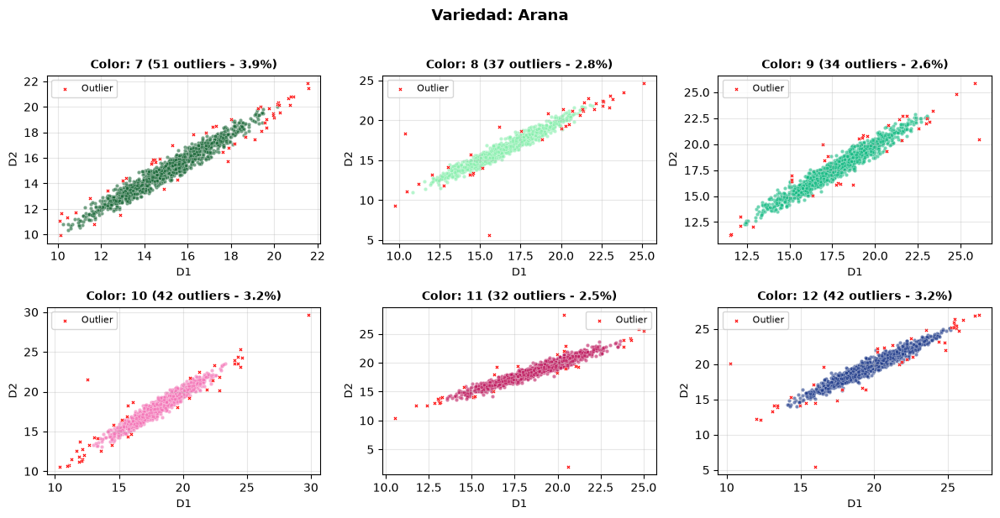

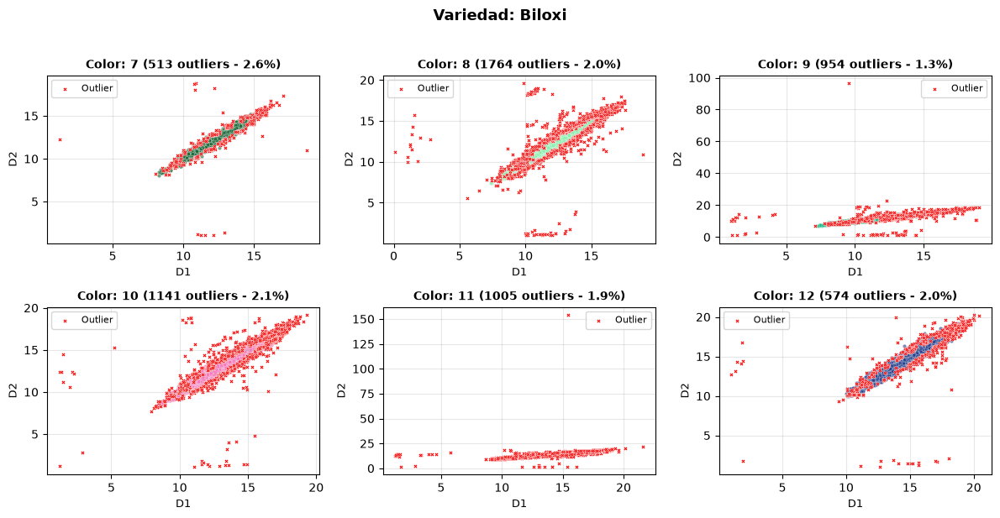

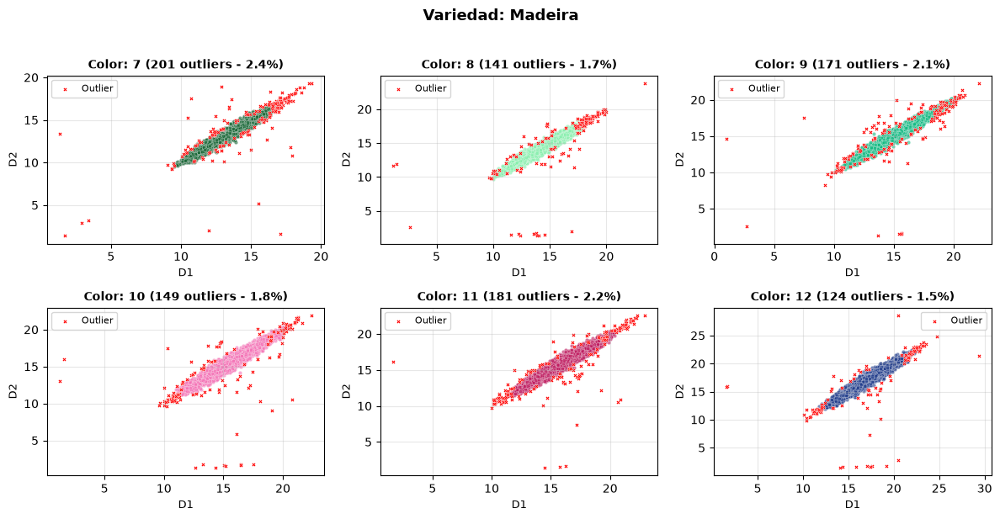

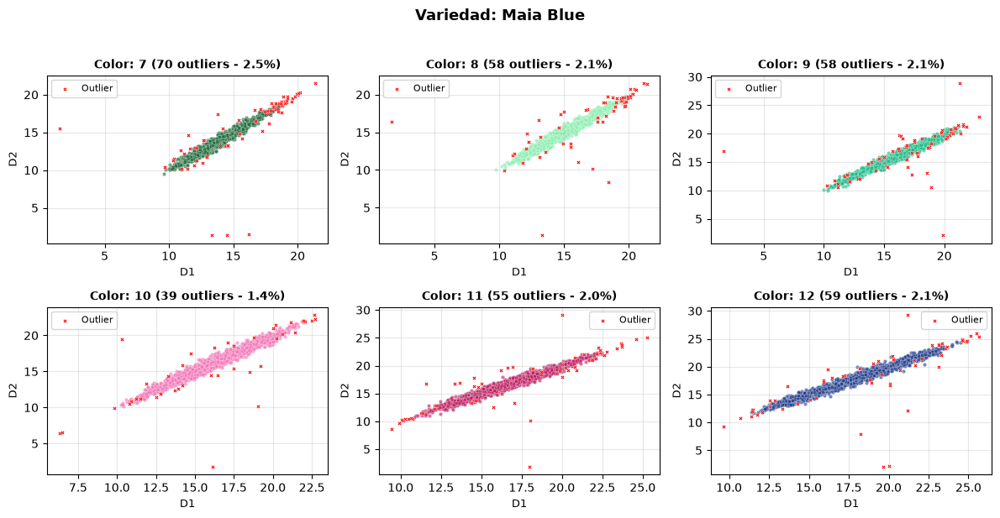

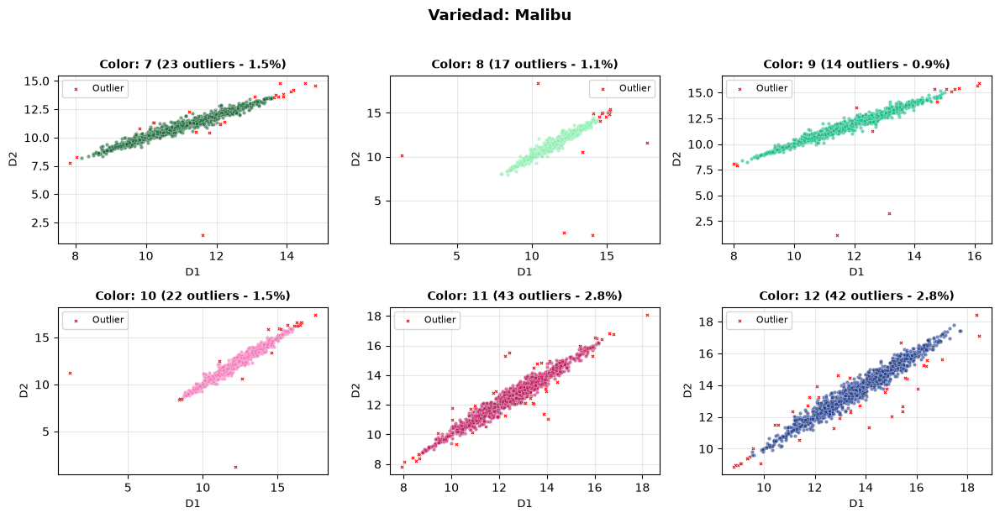

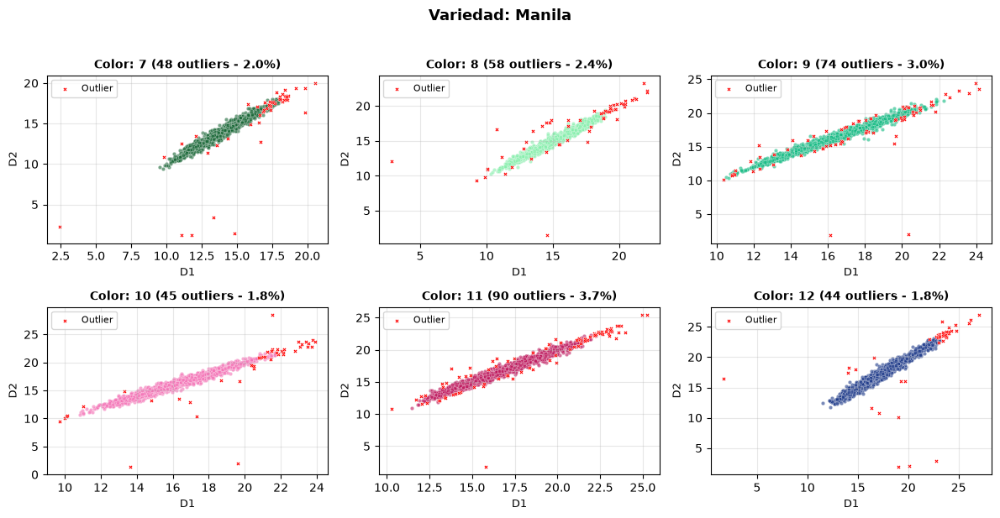

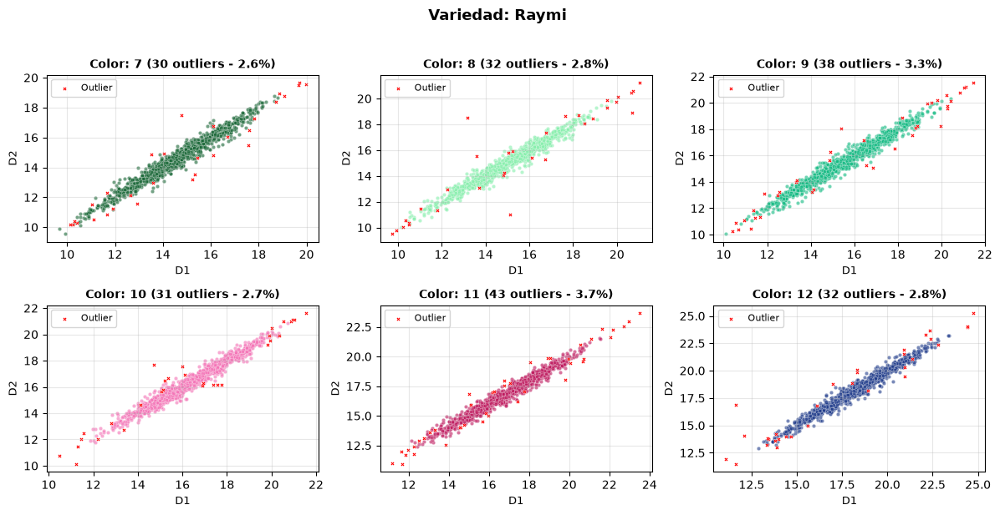

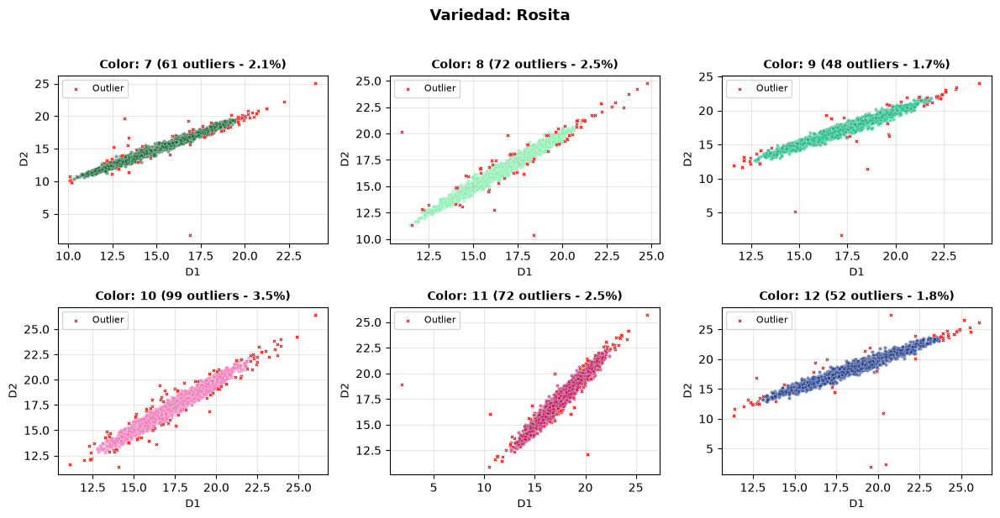

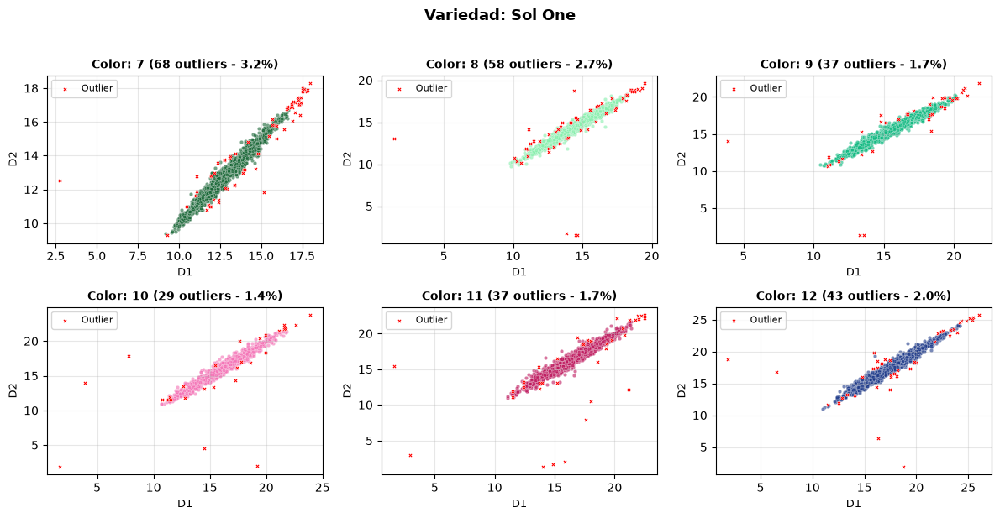

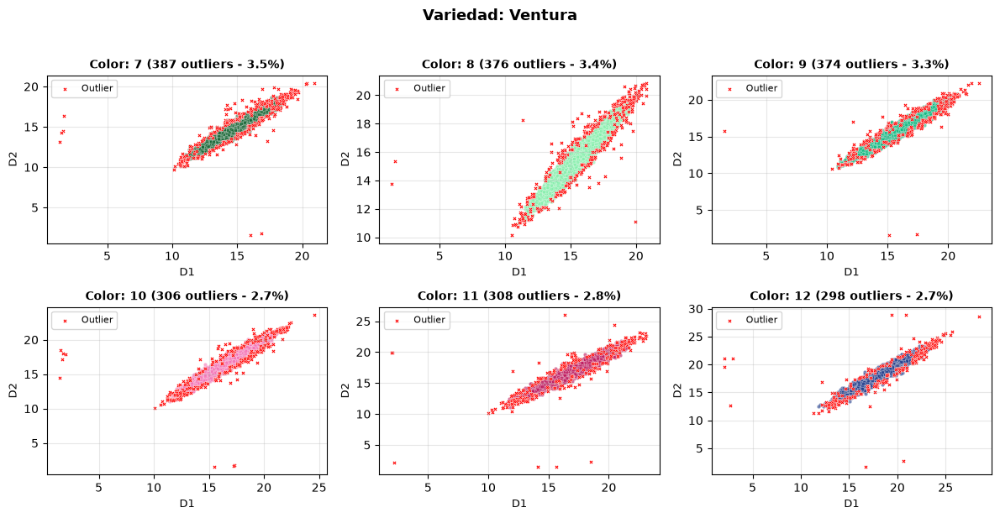

In [ ]:
# Visualizar outliers detectados
scatter_by_variedad_color(
    df_outliers, x='D1', y='D2',
    palette=PALETA_ARANDANO,
    outlier_col='es_outlier',
    point_size = 10,
    outlier_size = 10
)

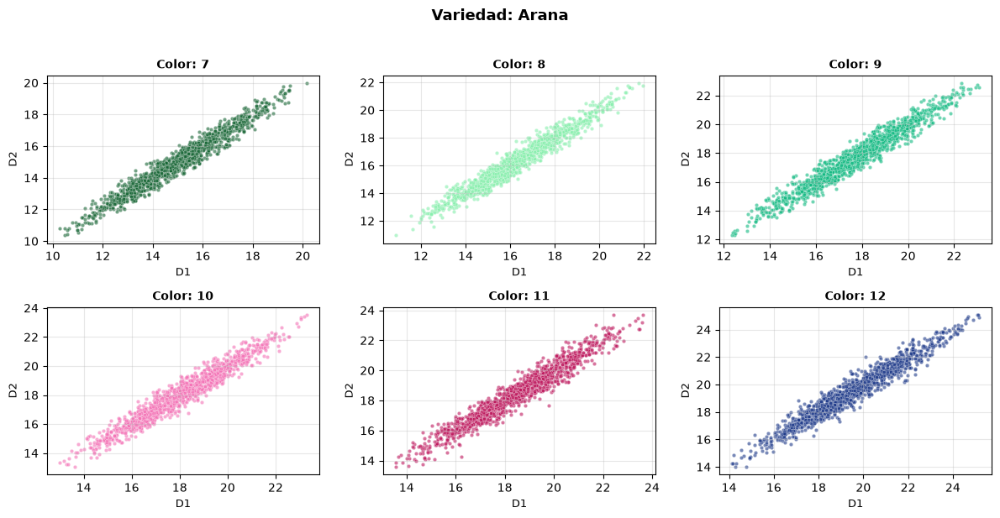

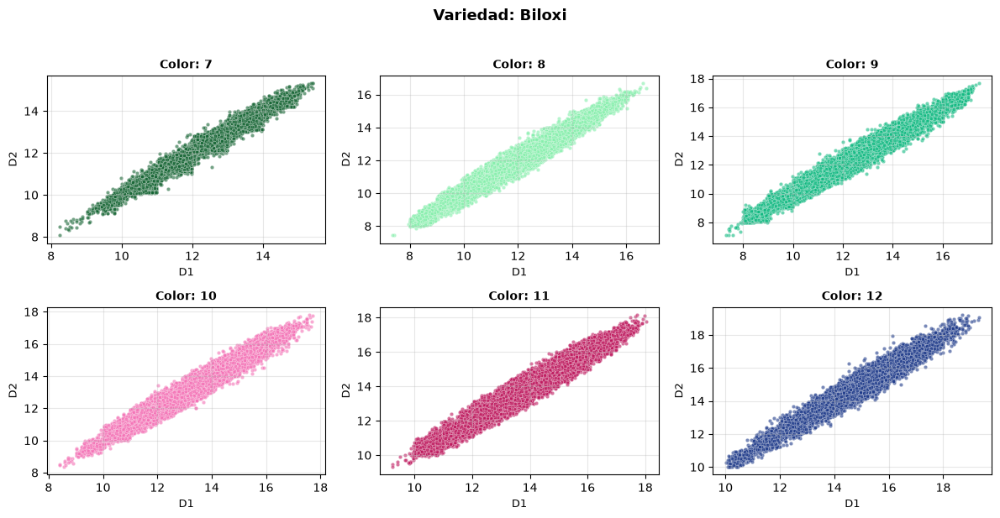

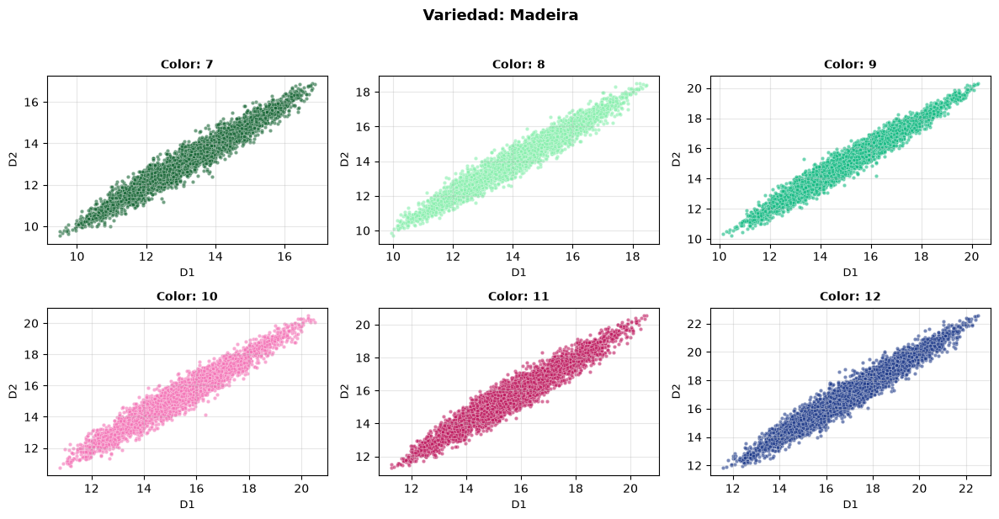

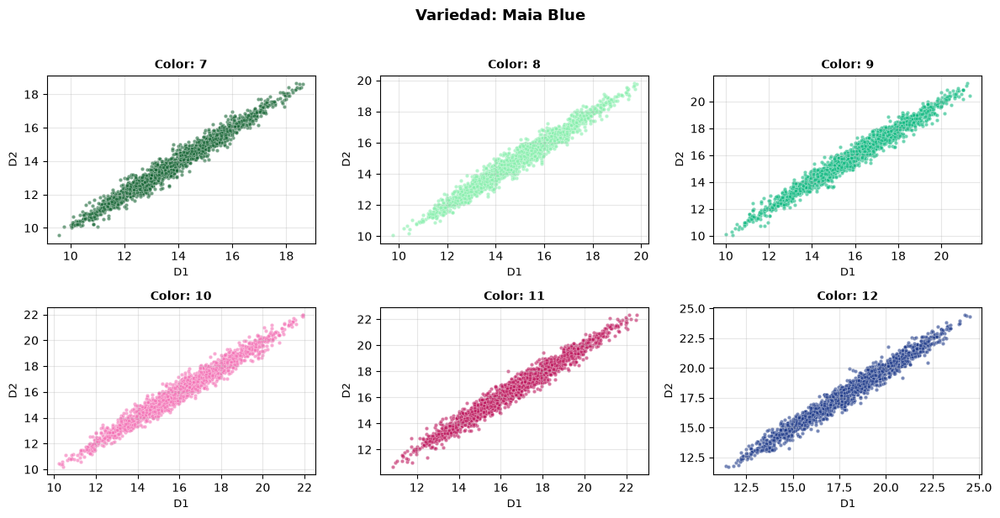

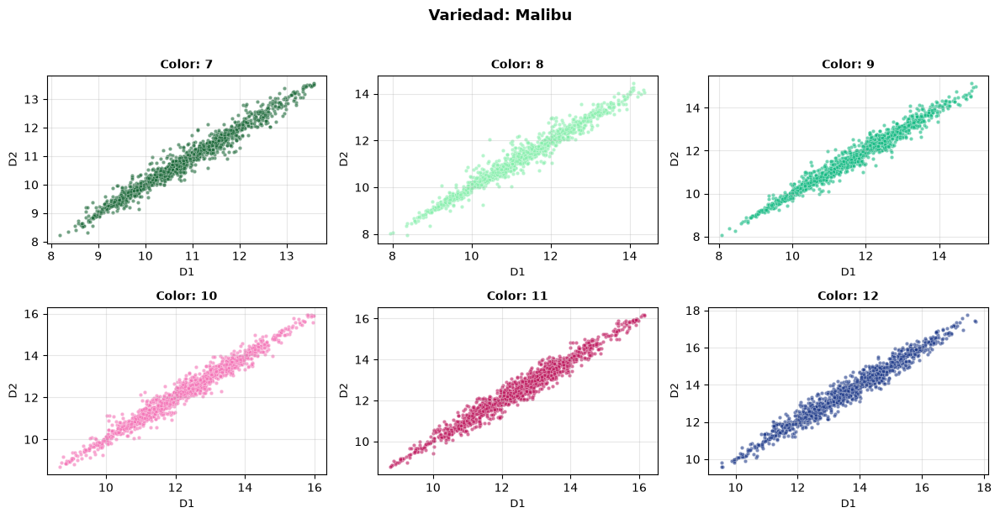

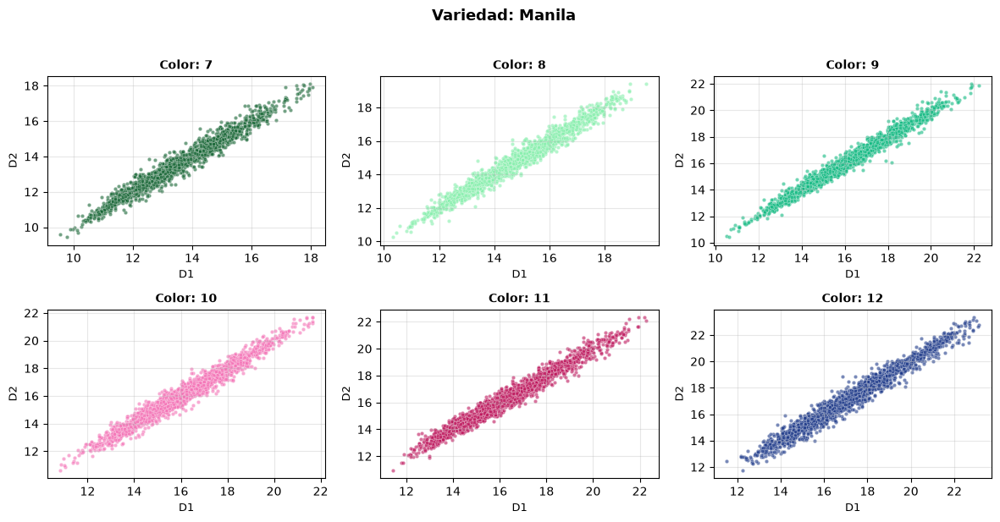

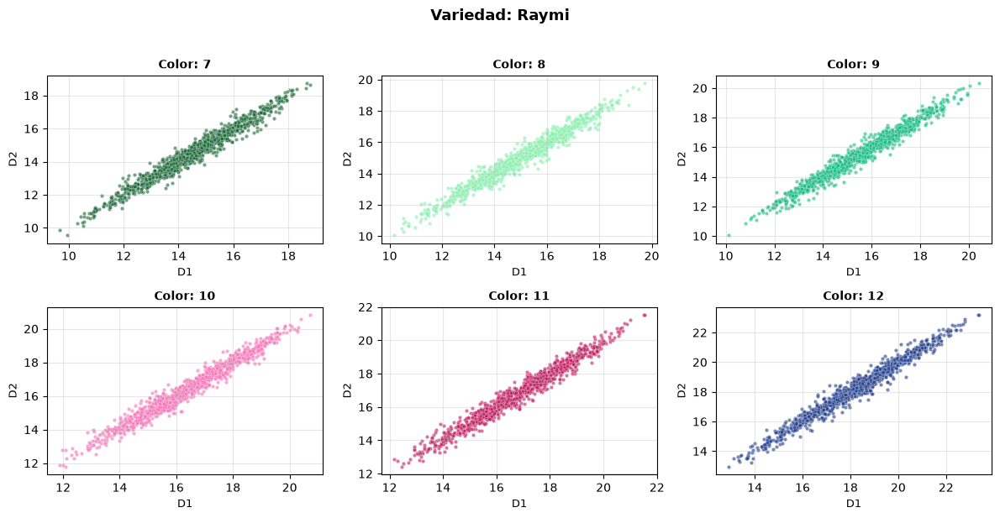

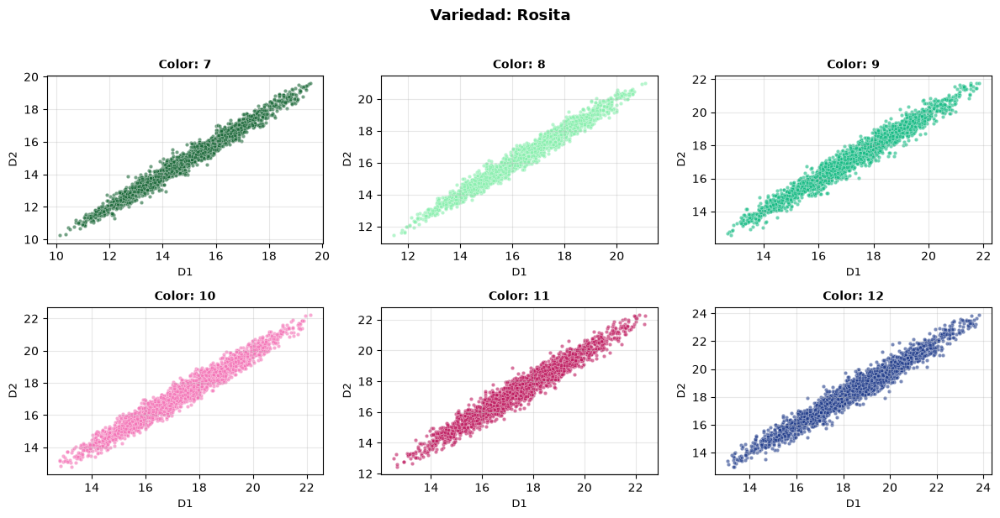

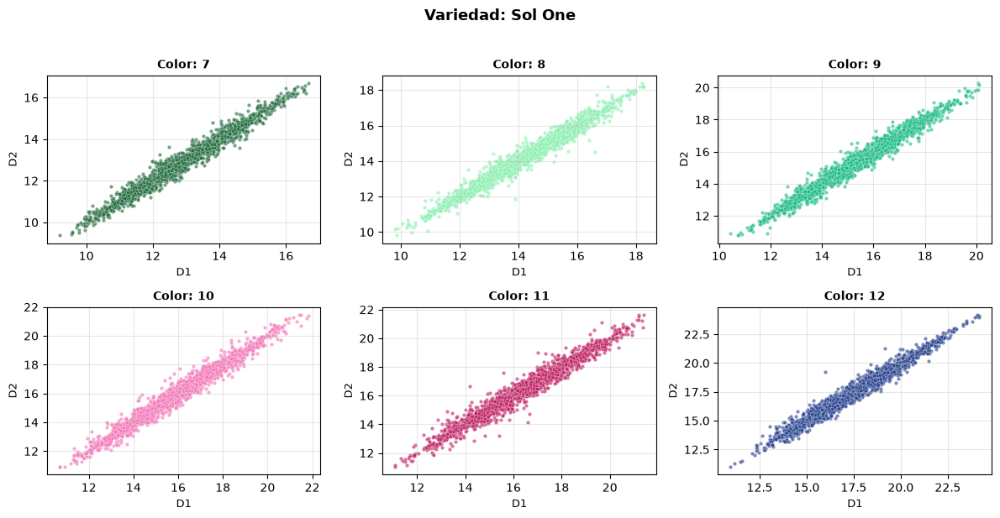

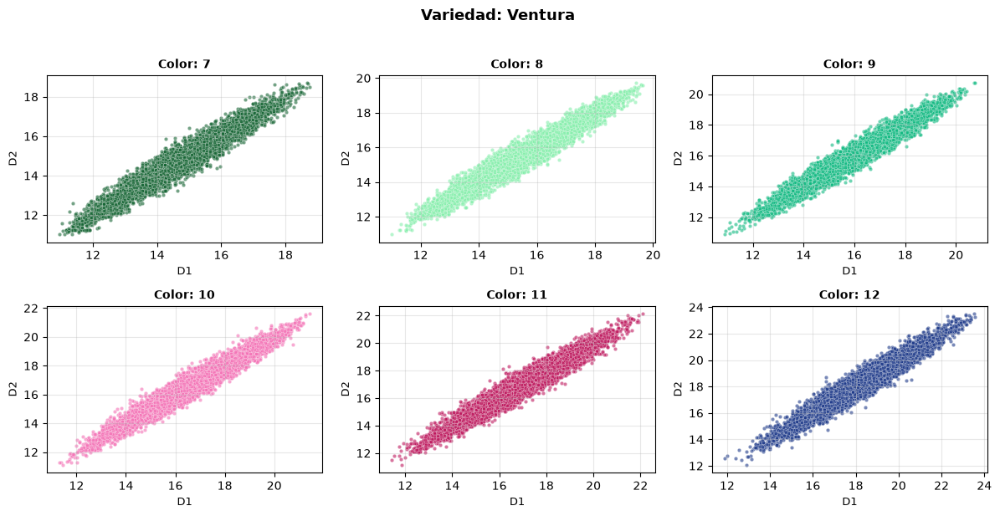

In [ ]:
# Visualizar sin outliers
scatter_by_variedad_color(
    df_outliers[df_outliers['es_outlier'] == 0], x='D1', y='D2',
    palette=PALETA_ARANDANO,
    point_size = 10
)

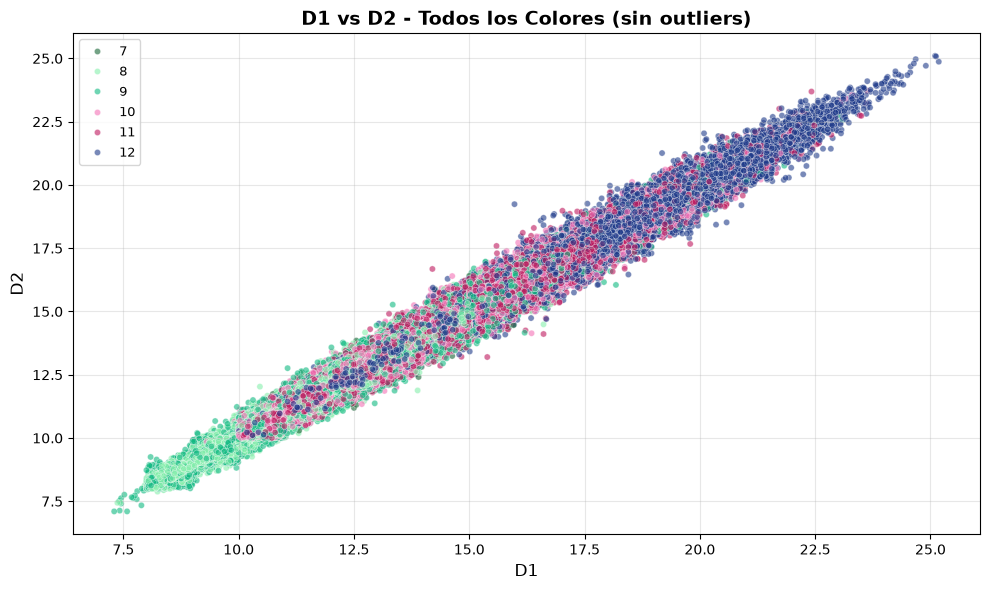

In [15]:
# Gráfico general - todos los colores (solo normales)
plt.figure(figsize=(10, 6))

normal = df_outliers[df_outliers['es_outlier'] == 0]
sns.scatterplot(data=normal, x='D1', y='D2', hue='Color', palette=PALETA_ARANDANO, alpha=0.6, s=20)

plt.title('D1 vs D2 - Todos los Colores (sin outliers)', fontsize=14, fontweight='bold')
plt.xlabel('D1', fontsize=12)
plt.ylabel('D2', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=9, loc='best')
plt.tight_layout()
plt.show()

In [ ]:
# Crear dataframe limpio (sin outliers de diámetro y con peso > 0)
df_limpio = df_outliers[
    (df_outliers['es_outlier'] == 0) &
    (df_outliers['Peso'] > 0)
].copy()

# Feature engineering: diámetro promedio
df_limpio['D_promedio'] = (df_limpio['D1'] + df_limpio['D2']) / 2

print(f"Registros después de limpiar outliers de diámetro: {len(df_limpio):,}")

Registros después de limpiar outliers de diámetro: 352,711


In [17]:
df_limpio[df_limpio['es_outlier'] == 0].describe()

,Id,Año,Semana,IdSubParcela,Muestra,Planta,Baya,Color,D1,D2,Peso,PesoEstimado,Duplicado,es_outlier,D_promedio
count,3.527110e+05,352711.0,352711.000000,352711.000000,352711.000000,352711.000000,352711.000000,352711.000000,352711.000000,352711.000000,352711.000000,344297.000000,352711.000000,352711.0,352711.000000
mean,1.661839e+08,2026.0,32.140855,3651.052085,1.000028,1.578613,61.325238,9.558568,14.576565,14.541651,1.492790,0.011265,0.000284,0.0,14.559108
std,3.224479e+06,0.0,9.663091,1043.418536,0.016838,0.686822,68.412572,1.684942,2.372098,2.395958,0.744253,0.001770,0.016836,0.0,2.378697
min,1.556015e+08,2026.0,2.000000,750.000000,1.000000,1.000000,1.000000,7.000000,7.950000,7.940000,0.020000,0.007000,0.000000,0.0,7.990000
25%,1.656643e+08,2026.0,30.000000,3982.000000,1.000000,1.000000,20.000000,8.000000,12.830000,12.800000,0.980000,0.012000,0.000000,0.0,12.785000
50%,1.670700e+08,2026.0,35.000000,4014.000000,1.000000,1.000000,40.000000,10.000000,14.330000,14.280000,1.320000,0.012000,0.000000,0.0,14.325000
75%,1.681591e+08,2026.0,38.000000,4059.000000,1.000000,2.000000,60.000000,11.000000,16.130000,16.120000,1.850000,0.012000,0.000000,0.0,16.135000
max,1.694102e+08,2026.0,43.000000,4108.000000,11.000000,4.000000,406.000000,12.000000,25.180000,25.100000,18.790000,0.012000,1.000000,0.0,25.100000


## 6. Detección de Outliers en Peso

Una vez filtradas las anomalías geométricas, se analiza la consistencia de la relación entre el **peso** y los **diámetros principales**.

### Método aplicado
Se ajusta una **regresión robusta tipo Huber** bajo una formulación logarítmica:

\[
\log(Peso) = f(\log(D1), \log(D2))
\]

Luego se calculan residuos robustos y se identifican observaciones atípicas cuando su desviación respecto al patrón esperado supera el umbral definido.

### Justificación
Este procedimiento permite detectar casos donde:

- los diámetros parecen plausibles,
- pero el peso no guarda una relación coherente con ellos.

Es decir, no se trata de outliers geométricos, sino de **outliers en la relación diámetro–peso**.

### Por qué se usa un enfoque robusto
La regresión Huber reduce la influencia de observaciones extremas durante el ajuste inicial, lo que mejora la capacidad para detectar registros realmente inconsistentes sin deformar la tendencia central.

### Resultado de esta fase
Se obtiene un dataset final más estable para entrenamiento, compuesto por observaciones que son consistentes tanto geométrica como funcionalmente.


In [18]:
def detectar_outliers_regresion_robusta(df_limpio, z_threshold=2.5, min_n=10):
    """
    Detecta outliers en peso usando regresión robusta + análisis de residuos.
    Agrupa por (Variedad, Color) para respetar rangos distintos por variedad.

    Modelo potencia en escala log-log:
        log(Peso) = alpha + b * log(D_promedio)

    Parameters
    ----------
    df_limpio : pd.DataFrame
        DataFrame con columnas 'Variedad', 'Color', 'D_promedio', 'Peso'.
    z_threshold : float, default 2.5
        Umbral para marcar outliers (z robusto MAD).
    min_n : int, default 10
        Mínimo de puntos por grupo para ajustar el modelo.

    Returns
    -------
    pd.DataFrame
        DataFrame con columna 'es_outlier_peso' (0/1).
    """
    df_result = df_limpio.copy()
    df_result["es_outlier_peso"] = 0

    # Limpieza básica
    df_result = df_result.replace([np.inf, -np.inf], np.nan)
    df_result = df_result.dropna(subset=["IdSubParcela", "Color", "D_promedio", "Peso"])

    # Umbral global
    grupos = df_result.groupby(["IdSubParcela", "Color"])

    for (IdSubParcela, color), grupo in grupos:
        df_grupo = df_result.loc[grupo.index].copy()

        if len(df_grupo) < min_n:
            continue

        # Log requiere valores > 0
        df_grupo = df_grupo[(df_grupo["D_promedio"] > 0) & (df_grupo["Peso"] > 0)]
        if len(df_grupo) < min_n:
            continue

        # Modelo potencia: log(Peso) = alpha + b * log(D_promedio)
        X = np.log(df_grupo[["D_promedio"]].values)
        y = np.log(df_grupo["Peso"].values)

        # Regresión robusta
        modelo = HuberRegressor(epsilon=1.35, max_iter=200)
        modelo.fit(X, y)

        # Residuos (en escala log)
        y_pred = modelo.predict(X)
        residuos = np.abs(y - y_pred)

        # Z robusto con MAD
        med = np.median(residuos)
        mad = np.median(np.abs(residuos - med))

        if mad == 0:
            q1, q3 = np.percentile(residuos, [25, 75])
            iqr = q3 - q1
            if iqr == 0:
                continue
            sigma_rob = iqr / 1.349
            z_robusto = np.abs(residuos - med) / sigma_rob
        else:
            z_robusto = 0.6745 * np.abs(residuos - med) / mad

        # Marcar outliers
        outliers_mask = z_robusto > z_threshold
        outliers_idx = df_grupo.index[outliers_mask]
        df_result.loc[outliers_idx, "es_outlier_peso"] = 1

    return df_result

In [ ]:
# Aplicar detección de outliers en peso
df_limpio_final = detectar_outliers_regresion_robusta(
    df_limpio,
    z_threshold=CONFIG['UMBRAL_OUTLIER_PESO']
)

n_outliers_peso = df_limpio_final['es_outlier_peso'].sum()
print(f"Outliers detectados (peso): {n_outliers_peso:,} ({100*n_outliers_peso/len(df_limpio_final):.1f}%)")

Outliers detectados (peso): 13,514 (3.8%)


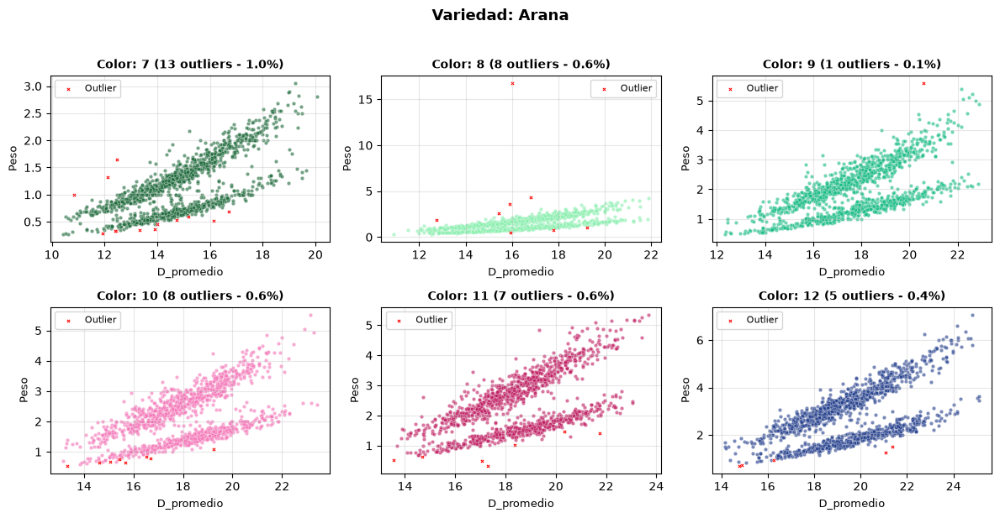

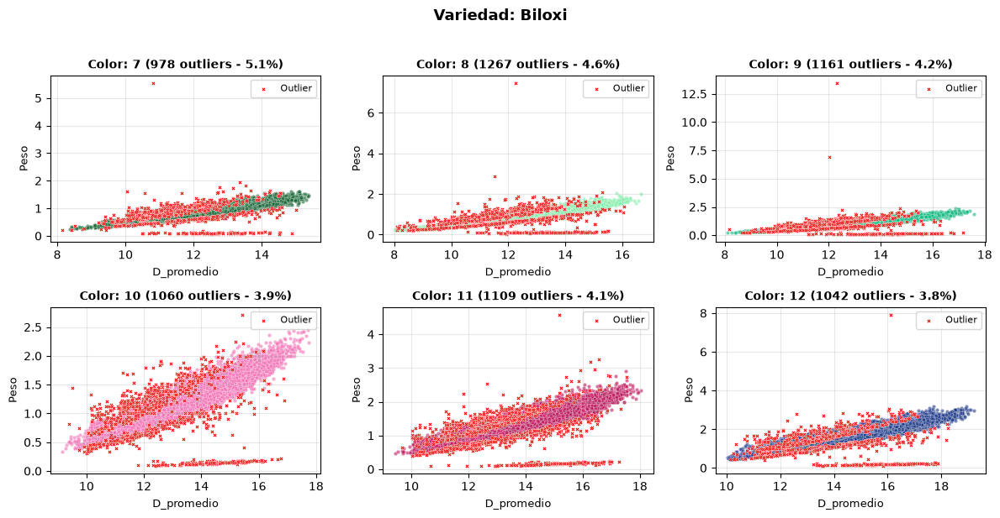

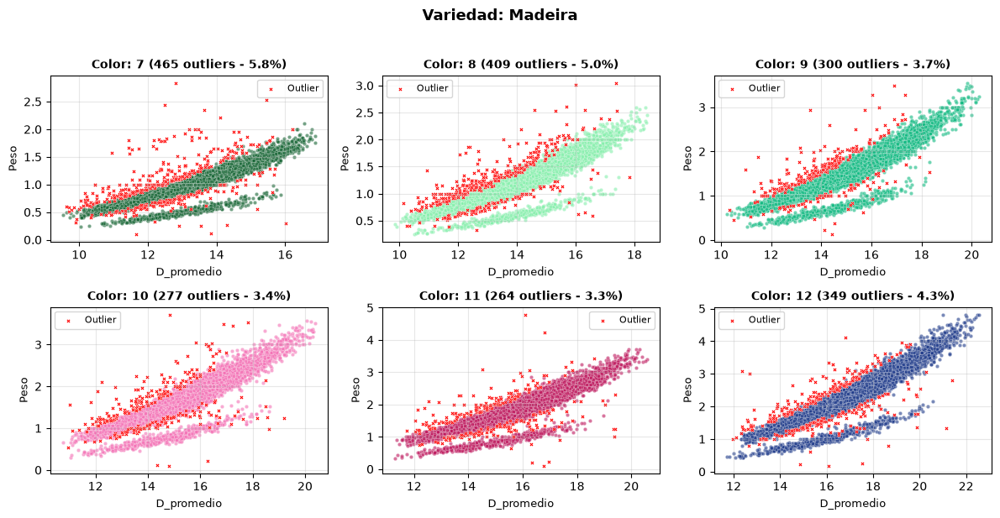

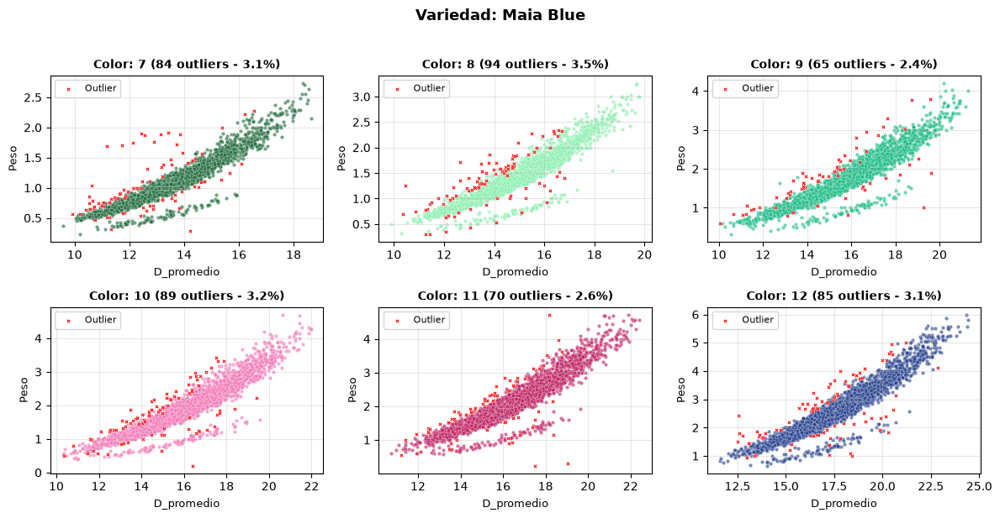

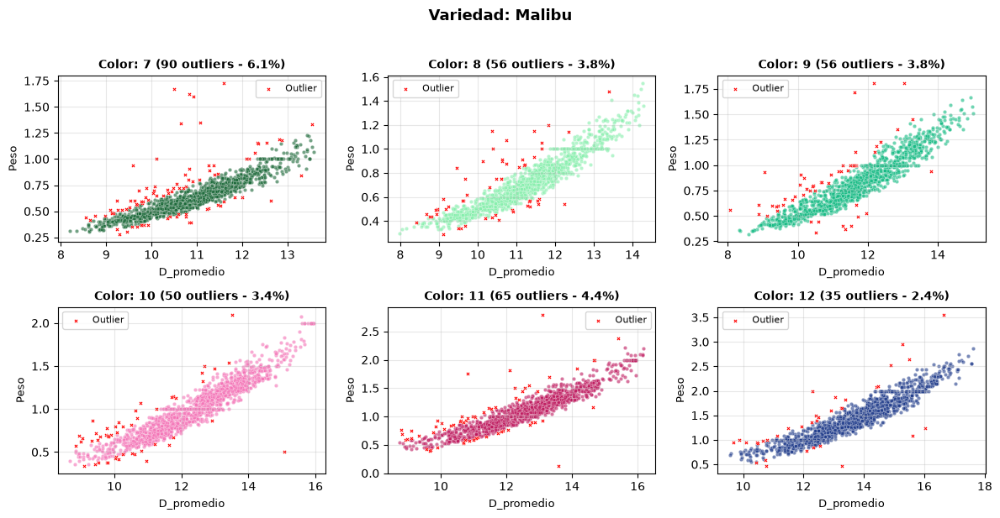

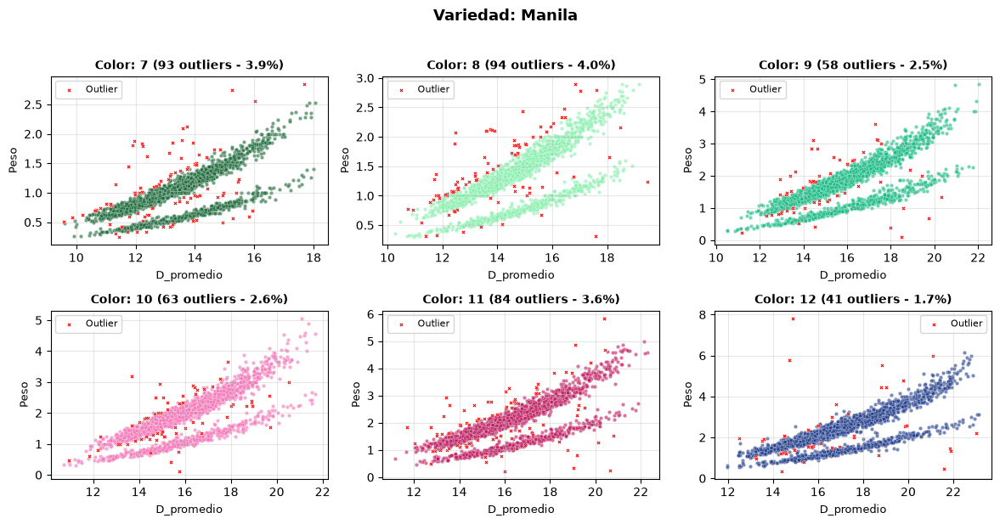

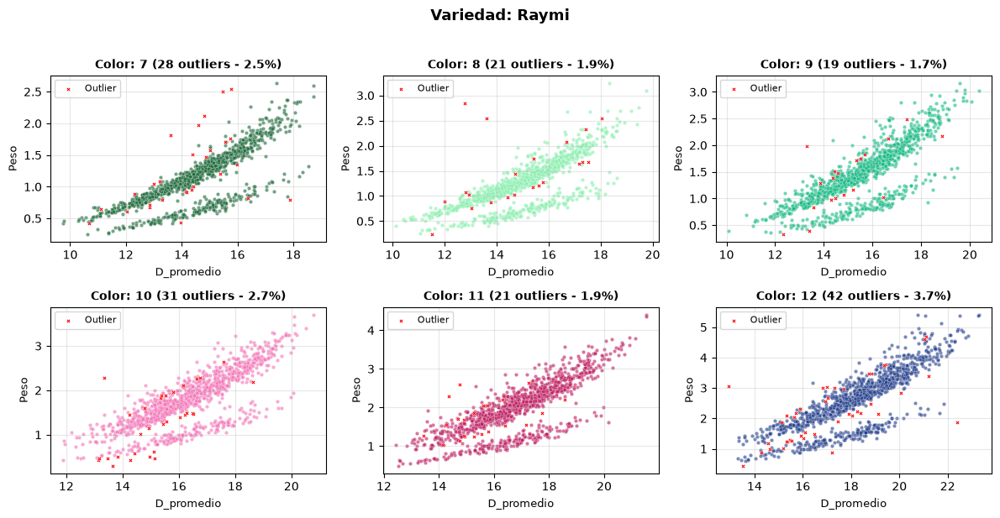

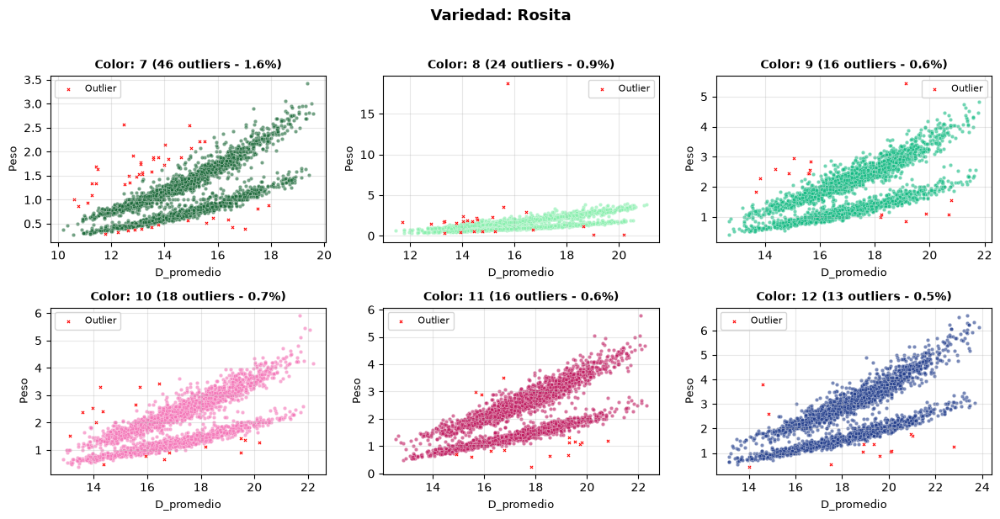

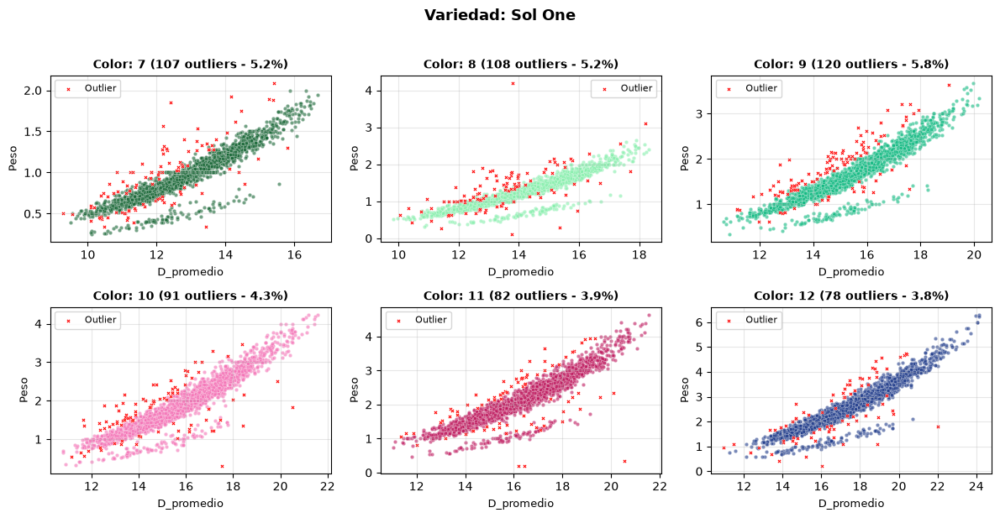

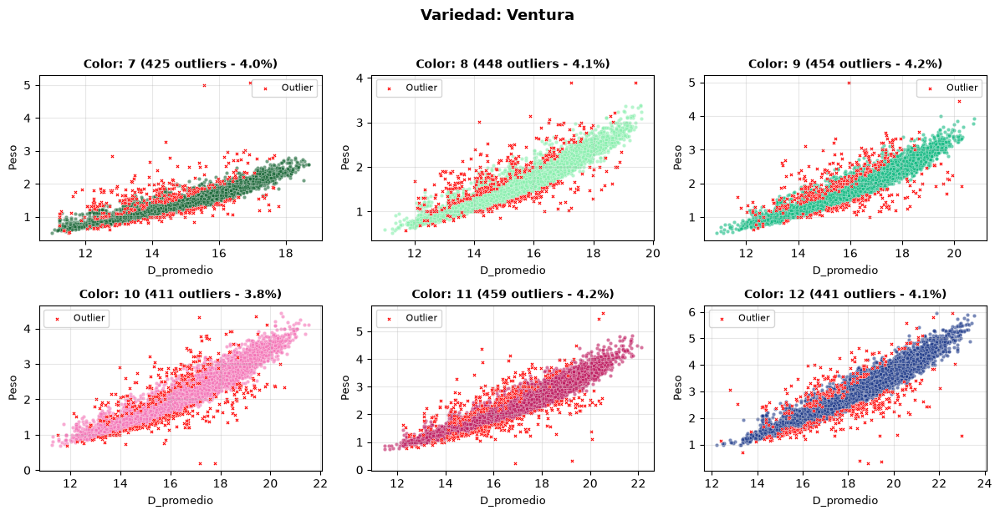

In [ ]:
# Visualizar outliers de peso
scatter_by_variedad_color(
    df_limpio_final, x='D_promedio', y='Peso',
    palette=PALETA_ARANDANO,
    outlier_col='es_outlier_peso',
    point_size = 10,
    outlier_size = 10
)

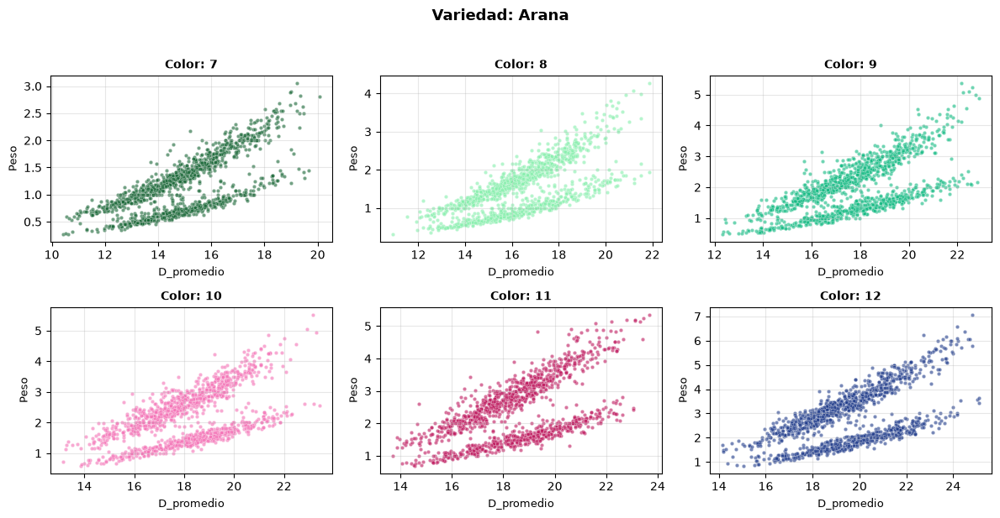

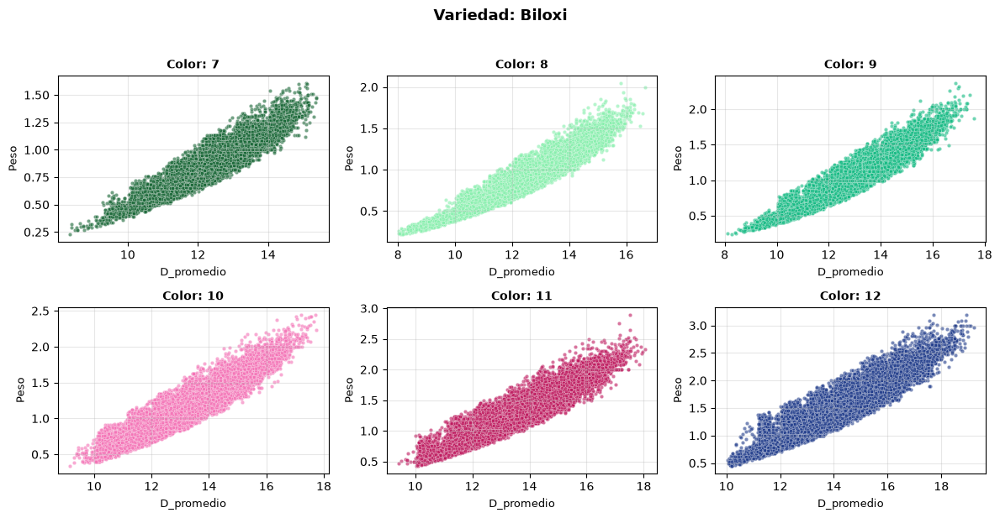

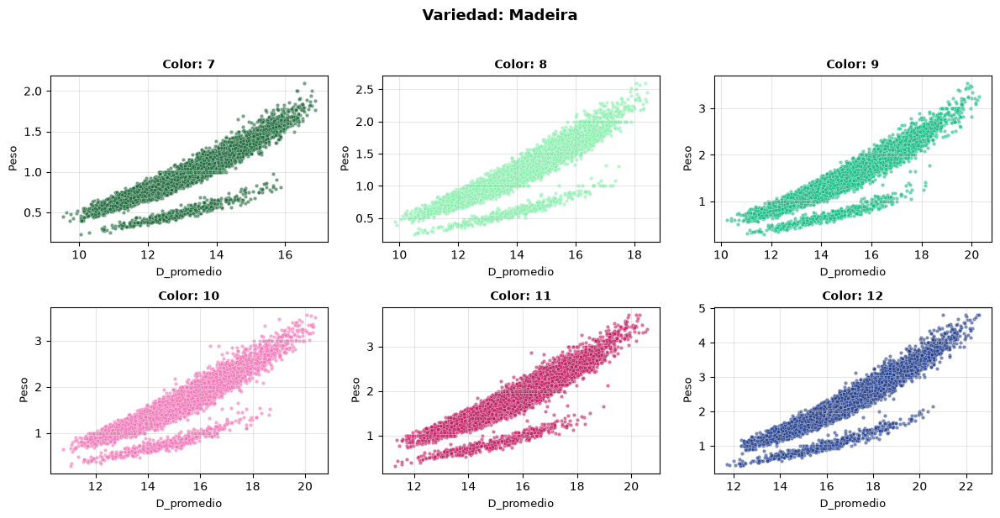

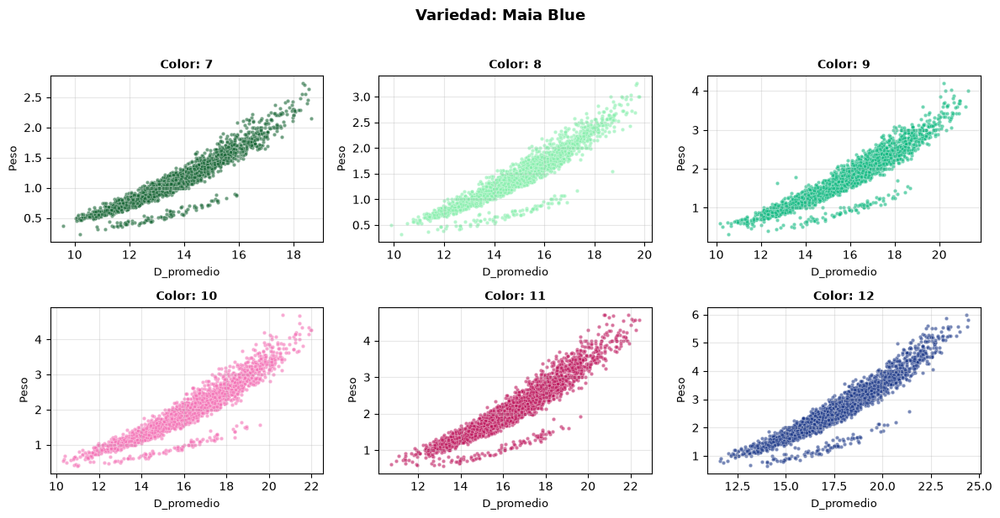

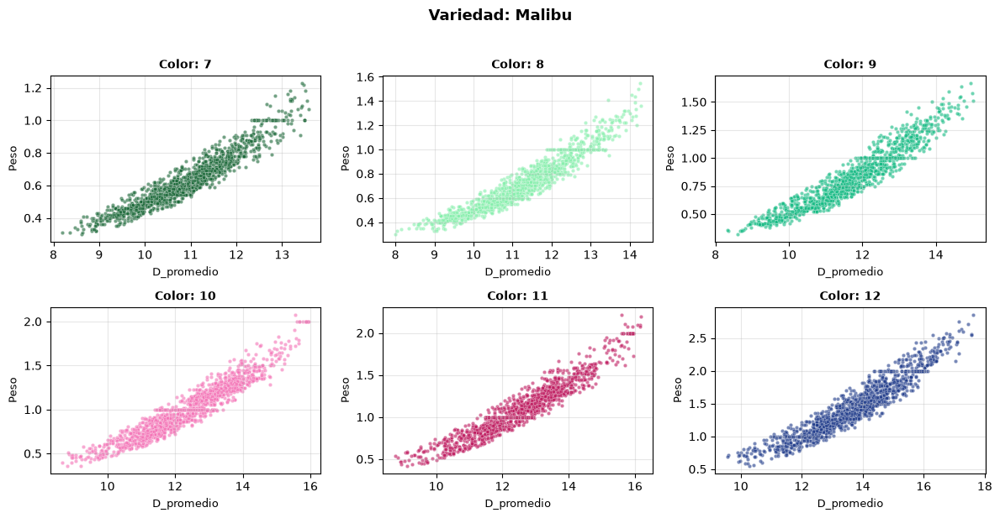

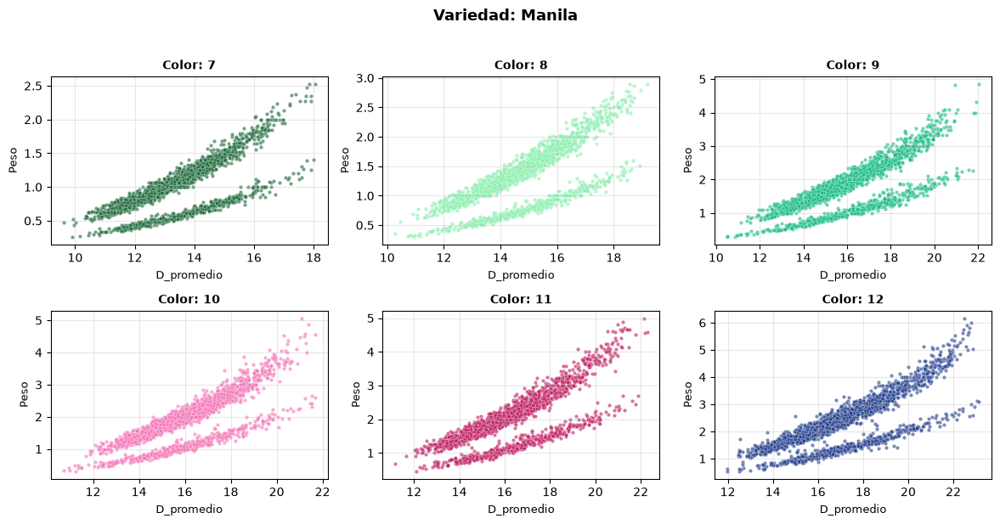

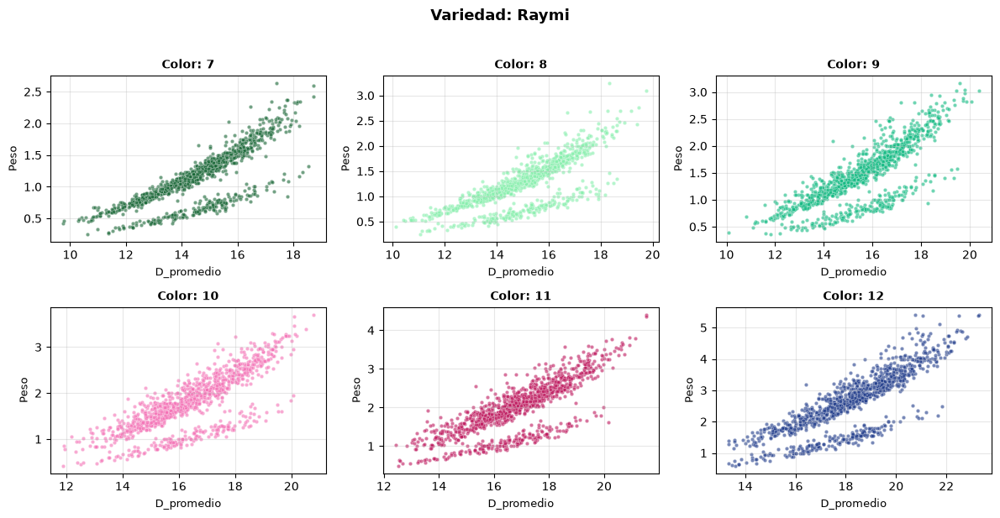

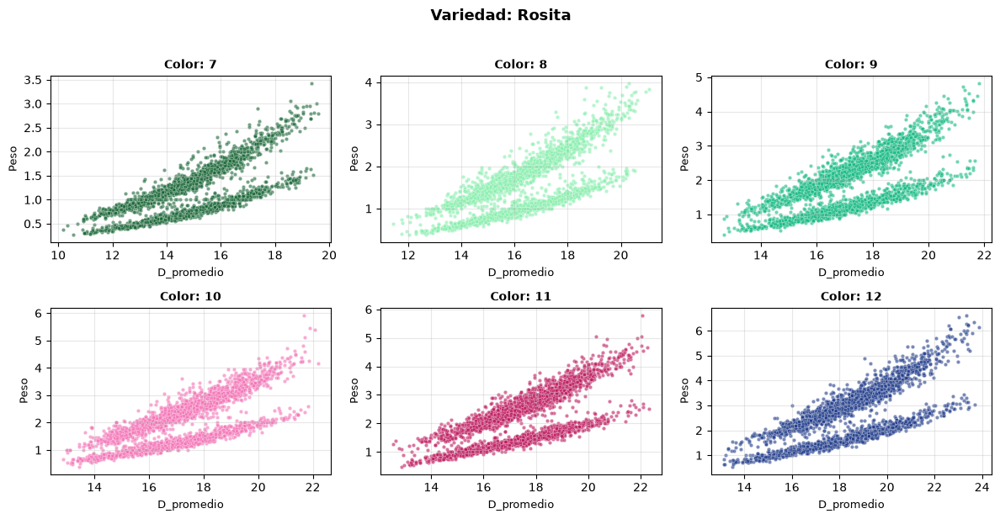

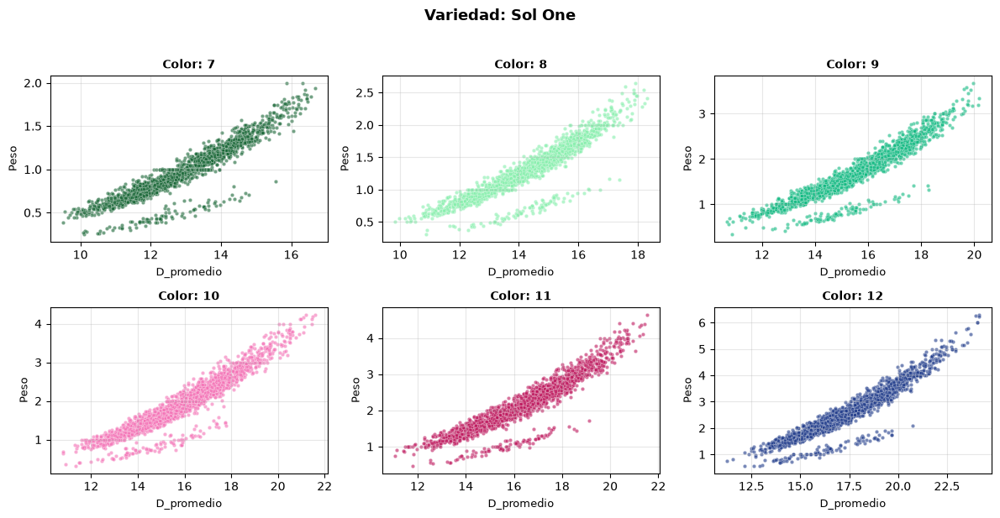

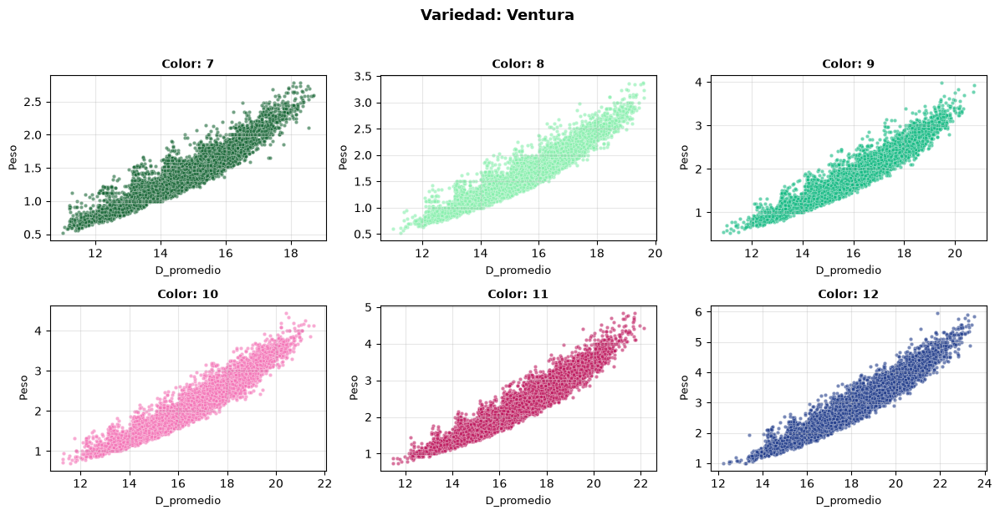

In [ ]:
# Visualizar solo datos limpios
scatter_by_variedad_color(
    df_limpio_final[df_limpio_final['es_outlier_peso'] == 0],
    x='D_promedio', y='Peso',
    palette=PALETA_ARANDANO,
    point_size = 10
)

In [22]:
df_limpio_final[df_limpio_final['es_outlier_peso'] == 0].describe()

,Id,Año,Semana,IdSubParcela,Muestra,Planta,Baya,Color,D1,D2,Peso,PesoEstimado,Duplicado,es_outlier,D_promedio,es_outlier_peso
count,3.391970e+05,339197.0,339197.000000,339197.000000,339197.0,339197.000000,339197.000000,339197.000000,339197.000000,339197.000000,339197.000000,331213.000000,339197.000000,339197.0,339197.000000,339197.0
mean,1.661911e+08,2026.0,32.159530,3654.241367,1.0,1.577744,61.208622,9.564141,14.610732,14.575202,1.499493,0.011270,0.000283,0.0,14.592967,0.0
std,3.209022e+06,0.0,9.619242,1039.854615,0.0,0.685593,68.308098,1.683743,2.368132,2.392095,0.740178,0.001765,0.016821,0.0,2.374812,0.0
min,1.556015e+08,2026.0,2.000000,750.000000,1.0,1.000000,1.000000,7.000000,7.950000,7.940000,0.220000,0.007000,0.000000,0.0,7.990000,0.0
25%,1.656746e+08,2026.0,30.000000,3982.000000,1.0,1.000000,20.000000,8.000000,12.870000,12.840000,0.990000,0.012000,0.000000,0.0,12.835000,0.0
50%,1.670686e+08,2026.0,35.000000,4014.000000,1.0,1.000000,40.000000,10.000000,14.360000,14.310000,1.330000,0.012000,0.000000,0.0,14.355000,0.0
75%,1.681565e+08,2026.0,38.000000,4059.000000,1.0,2.000000,60.000000,11.000000,16.160000,16.150000,1.860000,0.012000,0.000000,0.0,16.165000,0.0
max,1.694102e+08,2026.0,43.000000,4108.000000,1.0,4.000000,406.000000,12.000000,25.180000,25.100000,7.080000,0.012000,1.000000,0.0,25.100000,0.0


In [23]:
# Dataset final para modelado
df_limpio_final_peso = df_limpio_final[df_limpio_final['es_outlier_peso'] == 0].copy()
print(f"Dataset final para modelado: {len(df_limpio_final_peso):,} registros")

Dataset final para modelado: 339,197 registros


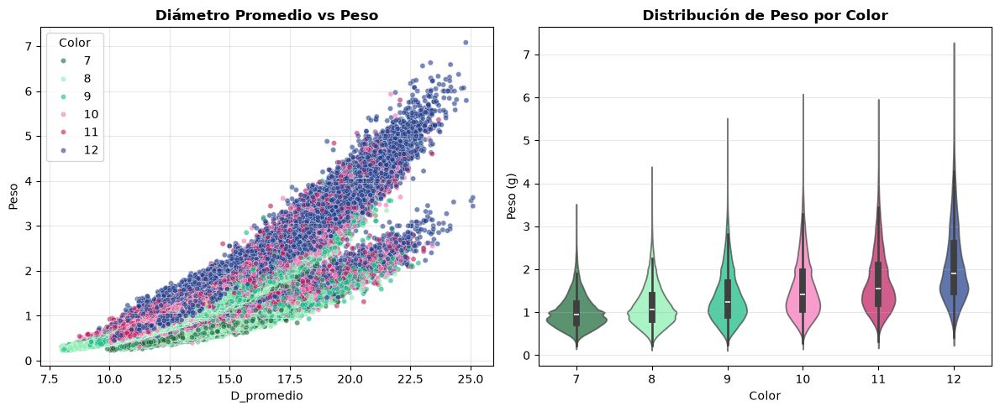

In [ ]:
# Gráficos exploratorios finales
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_limpio_final_peso, x='D_promedio', y='Peso',
    hue='Color', palette=PALETA_ARANDANO, alpha=0.6, s=20
)
plt.title('Diámetro Promedio vs Peso', fontweight='bold')
plt.grid(True, alpha=0.3)

# Distribución de peso por color (violin plot o box plot)
plt.subplot(1, 2, 2)
ax = sns.violinplot(data=df_limpio_final_peso, x='Color', y='Peso', alpha=0.7)

# Pintar cada violín con su color
for i, color in enumerate(sorted(df_limpio_final_peso['Color'].unique())):
    if color in PALETA_ARANDANO:
        ax.collections[i].set_facecolor(PALETA_ARANDANO[color])

plt.title('Distribución de Peso por Color', fontsize=12, fontweight='bold')
plt.xlabel('Color', fontsize=10)
plt.ylabel('Peso (g)', fontsize=10)
plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### Consolidación del dataset final para modelado

Después de aplicar ambas limpiezas, el notebook consolida el conjunto de observaciones que servirá de base para el entrenamiento.

### Criterios cumplidos por este dataset
Cada registro que ingresa al modelado ha pasado por:

1. validación geométrica en `D1` y `D2`;
2. validación funcional de la relación `Peso = f(D1, D2)`;
3. filtros básicos de integridad de datos.

Este paso es clave porque el rendimiento del modelo depende tanto de la técnica elegida como de la consistencia del conjunto de entrenamiento.


## 7. Entrenamiento de Modelos por `Variedad` y `Color`

Esta es la etapa central del notebook. Aquí se construyen modelos predictivos específicos por grupo, respetando la idea de que la relación entre diámetro y peso puede variar entre combinaciones de `Variedad` y `Color`.

### Enfoque principal
La relación base del modelado es:

\[
Peso = f(D1, D2)
\]

### Estrategia general
Para cada grupo `Variedad × Color` se ejecuta el siguiente flujo:

1. preparación de variables predictoras;
2. validación de cantidad mínima de datos;
3. definición de modelos candidatos;
4. evaluación con validación cruzada;
5. selección automática del mejor candidato;
6. entrenamiento final y medición en test.

### Criterio metodológico
No se impone un único modelo para todos los grupos.  
En su lugar, se permite que cada grupo seleccione la estructura que mejor representa su relación local entre diámetros y peso, reduciendo el riesgo de forzar una forma única sobre datos heterogéneos.


### 7.1 Preparación de variables predictoras

Se generan las variables que serán utilizadas por los distintos candidatos de modelado.

### Variable base
- `D1`
- `D2`

### Variables derivadas auxiliares
- `D_promedio`: resumen geométrico simple;
- `D_diff_abs`: diferencia absoluta entre diámetros;
- `D_area_proxy`: aproximación geométrica basada en el producto `D1 × D2`.

Aunque el enfoque principal trabaja con `D1` y `D2`, las variables derivadas se conservan para comparar si mejoran el desempeño en ciertos grupos sin reemplazar la base conceptual del notebook.


In [25]:
# =============================================================================
# FEATURES PARA MODELADO — base principal: D1 y D2
# =============================================================================
# D1 y D2 son las variables principales del modelo.
# Se crean algunas derivadas auxiliares solo para ciertos candidatos,
# pero la relación base es siempre Peso = f(D1, D2).

df_limpio_final_peso['D_promedio'] = (df_limpio_final_peso['D1'] + df_limpio_final_peso['D2']) / 2
df_limpio_final_peso['D_diff_abs'] = (df_limpio_final_peso['D1'] - df_limpio_final_peso['D2']).abs()
df_limpio_final_peso['D_area_proxy'] = df_limpio_final_peso['D1'] * df_limpio_final_peso['D2']

# Limpieza de infinitos
df_limpio_final_peso.replace([np.inf, -np.inf], np.nan, inplace=True)

cols_check = ['D1', 'D2', 'D_promedio', 'D_diff_abs', 'D_area_proxy']
print("NaN por columna:")
print(df_limpio_final_peso[cols_check].isna().sum())

NaN por columna:
D1              0
D2              0
D_promedio      0
D_diff_abs      0
D_area_proxy    0
dtype: int64


In [26]:
# =============================================================================
# VALIDACIÓN PRE-ENTRENAMIENTO
# =============================================================================
def validar_datos_entrenamiento(df, min_registros=50):
    resumen = (
        df.groupby(['Variedad', 'Color'])
        .size()
        .reset_index(name='N')
        .sort_values(['Variedad', 'Color'])
    )
    problemas = resumen[resumen['N'] < min_registros]
    if len(problemas) > 0:
        print("⚠️ Grupos con datos insuficientes:")
        for _, row in problemas.iterrows():
            print(f"   - {row['Variedad']} / Color {row['Color']}: {row['N']} registros")
    else:
        print("✅ Validación OK - Suficientes datos para todos los grupos")
    print(f"\nTotal grupos (Variedad × Color): {len(resumen)}")
    print(f"Grupos válidos (≥{min_registros}): {len(resumen[resumen['N'] >= min_registros])}")
    return resumen

resumen_datos = validar_datos_entrenamiento(df_limpio_final_peso, min_registros=50)
resumen_datos

✅ Validación OK - Suficientes datos para todos los grupos

Total grupos (Variedad × Color): 60
Grupos válidos (≥50): 60


,Variedad,Color,N
0,Arana,7,1236
1,Arana,8,1254
2,Arana,9,1265
3,Arana,10,1250
4,Arana,11,1261
5,Arana,12,1253
6,Biloxi,7,18377
7,Biloxi,8,26085
8,Biloxi,9,26437
9,Biloxi,10,26064


In [27]:
# =============================================================================
# MODELOS CANDIDATOS — enfoque principal Peso = f(D1, D2)
# =============================================================================
# Se priorizan modelos que usan D1 y D2 directamente.
# Se mantienen algunos candidatos auxiliares para comparar si una
# representación resumida o una proxy geométrica mejoran en ciertos grupos.
#
# NOTA — feature 'semana':
#   Se usa encoding cíclico (seno/coseno) para modelos lineales y SVR,
#   ya que semana ISO es cíclica (52 → 1 son contiguas).
#   El pipeline asume que el DataFrame ya contiene las columnas:
#       semana_seno   = np.sin(2 * np.pi * semana_iso / 52)
#       semana_coseno = np.cos(2 * np.pi * semana_iso / 52)
# =============================================================================

MODELOS_CANDIDATOS = [
    # -----------------------------------------------------------------
    # Grupo 1: D1, D2 — sin semana (baseline)
    # -----------------------------------------------------------------
    {
        'features': ['D1', 'D2'],
        'modelo': Pipeline([
            ('scaler', StandardScaler()),
            ('reg', Ridge(alpha=1.0))
        ]),
        'nombre': 'Ridge_D1D2'
    },
    {
        'features': ['D1', 'D2'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', Ridge(alpha=1.0))
        ]),
        'nombre': 'Ridge_Poly2_D1D2'
    },
    {
        'features': ['D1', 'D2'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', ElasticNet(alpha=0.01, l1_ratio=0.3, max_iter=10000))
        ]),
        'nombre': 'ElasticNet_Poly2_D1D2'
    },
    {
        'features': ['D1', 'D2'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=3, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', Ridge(alpha=1.0))
        ]),
        'nombre': 'Ridge_Poly3_D1D2'
    },
    {
        'features': ['D1', 'D2'],
        'modelo': Pipeline([
            ('scaler', StandardScaler()),
            ('reg', SVR(kernel='rbf', C=10, epsilon=0.05, gamma='scale'))
        ]),
        'nombre': 'SVR_RBF_D1D2'
    },
    {
        'features': ['D1', 'D2', 'D_diff_abs'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', Ridge(alpha=1.0))
        ]),
        'nombre': 'Ridge_Poly2_D1D2_Diff'
    },
    {
        'features': ['D_area_proxy', 'D_promedio'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', Ridge(alpha=0.5))
        ]),
        'nombre': 'Ridge_AreaPromedio'
    },

    # -----------------------------------------------------------------
    # Grupo 2: D1, D2 + semana (encoding cíclico)
    # Hipótesis: el peso varía temporalmente aunque D1/D2 sean iguales.
    # -----------------------------------------------------------------
    {
        'features': ['D1', 'D2', 'semana_seno', 'semana_coseno'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', Ridge(alpha=1.0))
        ]),
        'nombre': 'Ridge_Poly2_D1D2_Semana'
    },
    {
        'features': ['D1', 'D2', 'semana_seno', 'semana_coseno'],
        'modelo': Pipeline([
            ('poly', PolynomialFeatures(degree=2, include_bias=False)),
            ('scaler', StandardScaler()),
            ('reg', ElasticNet(alpha=0.01, l1_ratio=0.3, max_iter=10000))
        ]),
        'nombre': 'ElasticNet_Poly2_D1D2_Semana'
    },
    {
        'features': ['D1', 'D2', 'semana_seno', 'semana_coseno'],
        'modelo': Pipeline([
            ('scaler', StandardScaler()),
            ('reg', SVR(kernel='rbf', C=10, epsilon=0.05, gamma='scale'))
        ]),
        'nombre': 'SVR_RBF_D1D2_Semana'
    },
]

In [28]:
# Encoding cíclico de semana ISO — requerido por candidatos con semana
df_limpio_final_peso['semana_seno']   = np.sin(2 * np.pi * df_limpio_final_peso['Semana'] / 52)
df_limpio_final_peso['semana_coseno'] = np.cos(2 * np.pi * df_limpio_final_peso['Semana'] / 52)

In [29]:
# =============================================================================
# ENTRENAMIENTO CON SELECCIÓN AUTOMÁTICA POR (VARIEDAD, COLOR)
# =============================================================================
# Cambios clave:
# 1) CV con shuffle (KFold) para evitar sesgo por orden.
# 2) Selección SOLO con información del train (CV + gap train-vs-CV). El test NO participa en la elección.
# 3) Filtrado de filas con NaN en features del candidato.
# 4) Priorización práctica de modelos basados en D1 y D2.

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

modelos_finales = {}
metricas_resumen = []

cv = KFold(n_splits=5, shuffle=True, random_state=CONFIG['RANDOM_STATE'])

grupos = df_limpio_final_peso.groupby(['Variedad', 'Color'])

for (variedad, color), df_grupo in grupos:

    if len(df_grupo) < 30:
        print(f"⚠️ {variedad} / Color {color}: Insuficientes datos ({len(df_grupo)}), saltando...")
        continue

    # Split train/test (mismo para todos los modelos del grupo)
    idx_train, idx_test = train_test_split(
        df_grupo.index, test_size=CONFIG['TEST_SIZE'], random_state=CONFIG['RANDOM_STATE']
    )

    mejor_score = -np.inf
    mejor_config = None
    resultados_grupo = []

    for config in MODELOS_CANDIDATOS:
        features = config['features']

        # Subset + dropna para evitar fallos por NaN/inf
        df_train = df_grupo.loc[idx_train, features + ['Peso']].replace([np.inf, -np.inf], np.nan).dropna()
        df_test  = df_grupo.loc[idx_test,  features + ['Peso']].replace([np.inf, -np.inf], np.nan).dropna()

        # Si después de dropna quedan pocos datos, saltar
        if len(df_train) < 25 or len(df_test) < 5:
            continue

        X_train = df_train[features].to_numpy()
        y_train = df_train['Peso'].to_numpy()

        X_test  = df_test[features].to_numpy()
        y_test  = df_test['Peso'].to_numpy()

        modelo = clone(config['modelo'])

        # Cross-validation en train
        try:
            cv_scores = cross_val_score(modelo, X_train, y_train, cv=cv, scoring='r2')
            score_cv = float(np.mean(cv_scores))
            score_cv_std = float(np.std(cv_scores))
        except Exception as e:
            print(f"  ⚠️ {variedad}/Color {color} - {config['nombre']}: Error CV → {e}")
            continue

        # Entrenar en todo train
        modelo.fit(X_train, y_train)
        y_pred_train = modelo.predict(X_train)
        y_pred_test = modelo.predict(X_test)

        r2_train = r2_score(y_train, y_pred_train)
        r2_test = r2_score(y_test, y_pred_test)
        mae = mean_absolute_error(y_test, y_pred_test)
        rmse = float(np.sqrt(mean_squared_error(y_test, y_pred_test)))

        # Gap train-vs-CV (penaliza sobreajuste sin usar el test)
        gap_train_cv = r2_train - score_cv

        resultados_grupo.append({
            'nombre': config['nombre'],
            'features': features,
            'modelo': modelo,
            'score_cv': score_cv,
            'score_cv_std': score_cv_std,
            'r2_train': r2_train,
            'r2_test': r2_test,
            'mae': mae,
            'rmse': rmse,
            'gap_train_cv': gap_train_cv,
            'n_train': len(df_train),
            'n_test': len(df_test),
        })

        # Selección: CV medio - penalización por gap (si pasa umbral) - penalización leve por inestabilidad CV
        penal_gap = max(0.0, gap_train_cv - 0.05) * 0.5
        penal_std = score_cv_std * 0.15
        score_ajustado = score_cv - penal_gap - penal_std

        if score_ajustado > mejor_score:
            mejor_score = score_ajustado
            mejor_config = resultados_grupo[-1]

    if mejor_config is None:
        print(f"⚠️ {variedad} / Color {color}: Ningún modelo funcionó")
        continue

    print(
        f"✅ {variedad} / Color {color}: {mejor_config['nombre']} "
        f"(R²_CV={mejor_config['score_cv']:.4f}±{mejor_config['score_cv_std']:.4f}, "
        f"R²_Test={mejor_config['r2_test']:.4f}, N={len(df_grupo)})"
    )

    modelos_finales[(variedad, color)] = {
        'modelo': mejor_config['modelo'],
        'features': mejor_config['features'],
        'nombre': mejor_config['nombre'],
        'metricas': {
            'R2_CV': round(mejor_config['score_cv'], 4),
            'R2_CV_STD': round(mejor_config['score_cv_std'], 4),
            'R2_Train': round(mejor_config['r2_train'], 4),
            'R2_Test': round(mejor_config['r2_test'], 4),
            'MAE': round(float(mejor_config['mae']), 4),
            'RMSE': round(float(mejor_config['rmse']), 4),
            'Gap_Train_CV': round(float(mejor_config['gap_train_cv']), 4),
            'N_Train': int(mejor_config['n_train']),
            'N_Test': int(mejor_config['n_test']),
            'N_Total': int(len(df_grupo)),
        }
    }

    # Guardar TODOS para comparativa
    for res in resultados_grupo:
        metricas_resumen.append({
            'Variedad': variedad,
            'Color': color,
            'Estado': NOMBRES_COLOR.get(color, ''),
            'Modelo': res['nombre'],
            'Features': ','.join(res['features']),
            'R²_CV': round(res['score_cv'], 4),
            'R²_CV_STD': round(res['score_cv_std'], 4),
            'R²_Train': round(res['r2_train'], 4),
            'R²_Test': round(res['r2_test'], 4),
            'MAE (g)': round(float(res['mae']), 4),
            'RMSE (g)': round(float(res['rmse']), 4),
            'Gap_Train_CV': round(float(res['gap_train_cv']), 4),
            'Elegido': '✅' if res['nombre'] == mejor_config['nombre'] else '',
            'N_Train': int(res['n_train']),
            'N_Test': int(res['n_test']),
            'N_Total': int(len(df_grupo)),
        })

print("\n✅ Entrenamiento completado")

df_metricas = pd.DataFrame(metricas_resumen)

✅ Arana / Color 7: SVR_RBF_D1D2_Semana (R²_CV=0.8702±0.0252, R²_Test=0.9239, N=1236)
✅ Arana / Color 8: SVR_RBF_D1D2_Semana (R²_CV=0.8656±0.0291, R²_Test=0.8663, N=1254)
✅ Arana / Color 9: SVR_RBF_D1D2_Semana (R²_CV=0.8664±0.0088, R²_Test=0.8859, N=1265)
✅ Arana / Color 10: SVR_RBF_D1D2_Semana (R²_CV=0.8404±0.0192, R²_Test=0.8644, N=1250)
✅ Arana / Color 11: SVR_RBF_D1D2_Semana (R²_CV=0.8268±0.0227, R²_Test=0.8384, N=1261)
✅ Arana / Color 12: SVR_RBF_D1D2_Semana (R²_CV=0.8502±0.0266, R²_Test=0.8694, N=1253)
✅ Biloxi / Color 7: SVR_RBF_D1D2_Semana (R²_CV=0.8590±0.0049, R²_Test=0.8645, N=18377)
✅ Biloxi / Color 8: SVR_RBF_D1D2_Semana (R²_CV=0.9020±0.0035, R²_Test=0.9015, N=26085)
✅ Biloxi / Color 9: SVR_RBF_D1D2_Semana (R²_CV=0.9039±0.0017, R²_Test=0.9028, N=26437)
✅ Biloxi / Color 10: SVR_RBF_D1D2_Semana (R²_CV=0.8891±0.0026, R²_Test=0.8849, N=26064)
✅ Biloxi / Color 11: SVR_RBF_D1D2_Semana (R²_CV=0.8635±0.0039, R²_Test=0.8636, N=26147)
✅ Biloxi / Color 12: SVR_RBF_D1D2_Semana (R²_CV=0.

In [30]:
# =============================================================================
# RESUMEN DE MÉTRICAS
# =============================================================================
df_metricas = pd.DataFrame(metricas_resumen)
df_metricas = df_metricas.round(5)
df_metricas

,Variedad,Color,Estado,Modelo,Features,R²_CV,R²_CV_STD,R²_Train,R²_Test,MAE (g),RMSE (g),Gap_Train_CV,Elegido,N_Train,N_Test,N_Total
0,Arana,7,Pintón 1,Ridge_D1D2,"D1,D2",0.5118,0.0767,0.5256,0.4800,0.3151,0.3611,0.0138,,988,248,1236
1,Arana,7,Pintón 1,Ridge_Poly2_D1D2,"D1,D2",0.5229,0.0768,0.5370,0.4971,0.3079,0.3551,0.0141,,988,248,1236
2,Arana,7,Pintón 1,ElasticNet_Poly2_D1D2,"D1,D2",0.5209,0.0765,0.5341,0.4920,0.3115,0.3569,0.0132,,988,248,1236
3,Arana,7,Pintón 1,Ridge_Poly3_D1D2,"D1,D2",0.5226,0.0766,0.5369,0.4961,0.3077,0.3554,0.0144,,988,248,1236
4,Arana,7,Pintón 1,SVR_RBF_D1D2,"D1,D2",0.4363,0.1153,0.4646,0.3420,0.3039,0.4062,0.0283,,988,248,1236
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,Ventura,12,Azul (Maduro),Ridge_Poly2_D1D2_Diff,"D1,D2,D_diff_abs",0.9246,0.0016,0.9248,0.9210,0.1740,0.2263,0.0002,,8316,2080,10396
596,Ventura,12,Azul (Maduro),Ridge_AreaPromedio,"D_area_proxy,D_promedio",0.9236,0.0016,0.9237,0.9197,0.1749,0.2280,0.0001,,8316,2080,10396
597,Ventura,12,Azul (Maduro),Ridge_Poly2_D1D2_Semana,"D1,D2,semana_seno,semana_coseno",0.9262,0.0016,0.9264,0.9225,0.1730,0.2240,0.0002,,8316,2080,10396
598,Ventura,12,Azul (Maduro),ElasticNet_Poly2_D1D2_Semana,"D1,D2,semana_seno,semana_coseno",0.9243,0.0017,0.9244,0.9199,0.1759,0.2279,0.0001,,8316,2080,10396


### Interpretación del resumen de métricas

El cuadro de métricas permite revisar, por grupo, el comportamiento del modelo seleccionado.

### Indicadores principales
- **R²**: proporción de variabilidad explicada;
- **MAE**: error absoluto medio;
- **RMSE**: penaliza más fuertemente errores grandes;
- **CV score** y brechas entre entrenamiento y validación: ayudan a controlar sobreajuste.

La selección no se basa únicamente en el mejor ajuste en entrenamiento, sino en el equilibrio entre capacidad predictiva, estabilidad y generalización.


## 8. Exportación de Modelos

Una vez seleccionados y entrenados los modelos finales, se exportan a disco para su reutilización posterior.

### Propósito
La exportación permite separar:

- la fase de entrenamiento,
- de la fase de predicción operativa.

### Contenido exportado
Cada archivo guardado contiene, como mínimo:

- el modelo entrenado,
- las variables (`features`) utilizadas,
- la `Variedad`,
- el `Color`,
- y metadatos de trazabilidad útiles para uso posterior.

Esto garantiza que la predicción futura respete exactamente la estructura con la que fue entrenado cada modelo.


In [31]:
output_dir = Path(CONFIG['OUTPUT_DIR'])
output_dir.mkdir(parents=True, exist_ok=True)

metadata_comun = {
    'version': CONFIG['MODELO_VERSION'],
    'fecha_entrenamiento': datetime.now().isoformat(),
    'sklearn_version': sklearn.__version__,
    'fecha_datos_desde': CONFIG['FECHA_MINIMA'],
    'umbral_outlier_diametro': CONFIG['UMBRAL_OUTLIER_DIAMETRO'],
    'umbral_outlier_peso': CONFIG['UMBRAL_OUTLIER_PESO'],
    'features_encoding': {
        'semana_seno':   'np.sin(2 * np.pi * Semana / 52)',
        'semana_coseno': 'np.cos(2 * np.pi * Semana / 52)',
    }
}

FEATURES_DERIVADAS_SEMANA = {'semana_seno', 'semana_coseno'}

for (variedad, color), info in modelos_finales.items():
    filename = output_dir / f"modelo_peso_{variedad}_color_{color}.pkl"

    features_modelo = info['features']
    requiere_semana = bool(FEATURES_DERIVADAS_SEMANA & set(features_modelo))

    paquete = {
        'modelo':          info['modelo'],
        'features':        features_modelo,
        'nombre':          info['nombre'],
        'metricas':        info['metricas'],
        'metadata':        metadata_comun,
        'variedad':        variedad,
        'color':           color,
        'estado_madurez':  NOMBRES_COLOR.get(color, ''),
        'requiere_semana': requiere_semana,   # flag explícito para inferencia
    }

    joblib.dump(paquete, filename)
    print(f"✅ {filename}  [semana={'sí' if requiere_semana else 'no'}]")

print(f"\n📁 Modelos guardados en: {output_dir.absolute()}")

✅ modelos\modelo_peso_Arana_color_7.pkl  [semana=sí]
✅ modelos\modelo_peso_Arana_color_8.pkl  [semana=sí]
✅ modelos\modelo_peso_Arana_color_9.pkl  [semana=sí]
✅ modelos\modelo_peso_Arana_color_10.pkl  [semana=sí]
✅ modelos\modelo_peso_Arana_color_11.pkl  [semana=sí]
✅ modelos\modelo_peso_Arana_color_12.pkl  [semana=sí]
✅ modelos\modelo_peso_Biloxi_color_7.pkl  [semana=sí]
✅ modelos\modelo_peso_Biloxi_color_8.pkl  [semana=sí]
✅ modelos\modelo_peso_Biloxi_color_9.pkl  [semana=sí]
✅ modelos\modelo_peso_Biloxi_color_10.pkl  [semana=sí]
✅ modelos\modelo_peso_Biloxi_color_11.pkl  [semana=sí]
✅ modelos\modelo_peso_Biloxi_color_12.pkl  [semana=sí]
✅ modelos\modelo_peso_Madeira_color_7.pkl  [semana=sí]
✅ modelos\modelo_peso_Madeira_color_8.pkl  [semana=sí]
✅ modelos\modelo_peso_Madeira_color_9.pkl  [semana=sí]
✅ modelos\modelo_peso_Madeira_color_10.pkl  [semana=sí]
✅ modelos\modelo_peso_Madeira_color_11.pkl  [semana=sí]
✅ modelos\modelo_peso_Madeira_color_12.pkl  [semana=sí]
✅ modelos\modelo_pe

## 9. Predicción de Uso Operativo

En esta sección se muestra cómo reutilizar los modelos exportados para estimar peso sobre nuevos registros o sobre datasets preparados para operación.

### Lógica aplicada
La función de predicción:

1. carga todos los modelos disponibles;
2. identifica el grupo correspondiente de cada fila (`Variedad × Color`);
3. recupera el conjunto de variables requerido por el modelo de ese grupo;
4. genera el peso predicho.

### Importancia de esta sección
Aquí se materializa el objetivo práctico del notebook: convertir el entrenamiento previo en una herramienta reutilizable para estimación operativa.


In [32]:
def predecir_peso_df(df, directorio_modelos='./modelos/'):
    """
    Predice peso para todas las filas del DataFrame usando el modelo
    correspondiente a cada combinación (Variedad, Color).
    Base principal del modelado: Peso = f(D1, D2)
    """
    df = df.copy()
    df['Peso_Predicho'] = np.nan

    # Derivadas auxiliares requeridas por algunos candidatos
    if 'D_promedio' not in df.columns:
        df['D_promedio'] = (df['D1'] + df['D2']) / 2
    if 'D_diff_abs' not in df.columns:
        df['D_diff_abs'] = (df['D1'] - df['D2']).abs()
    if 'D_area_proxy' not in df.columns:
        df['D_area_proxy'] = df['D1'] * df['D2']

    # Cargar modelos una sola vez
    modelos = {}
    for filepath in Path(directorio_modelos).glob("modelo_peso_*.pkl"):
        paquete = joblib.load(filepath)
        key = (paquete['variedad'], paquete['color'])
        modelos[key] = paquete

    # Encoding cíclico de semana — solo si al menos un modelo lo requiere
    alguno_requiere_semana = any(p.get('requiere_semana', False) for p in modelos.values())
    if alguno_requiere_semana:
        if 'Semana' not in df.columns:
            raise ValueError("Al menos un modelo requiere 'Semana' pero la columna no existe en el DataFrame.")

        if 'semana_seno' not in df.columns:
            df['semana_seno'] = np.sin(2 * np.pi * df['Semana'] / 52)

        if 'semana_coseno' not in df.columns:
            df['semana_coseno'] = np.cos(2 * np.pi * df['Semana'] / 52)

    # Predecir por (Variedad, Color)
    for (variedad, color), paquete in modelos.items():
        mask = (df['Variedad'] == variedad) & (df['Color'] == color)
        if not mask.any():
            continue

        modelo = paquete['modelo']
        features = paquete['features']

        X = df.loc[mask, features].replace([np.inf, -np.inf], np.nan)
        valid = X.notna().all(axis=1)
        if valid.any():
            df.loc[mask & valid, 'Peso_Predicho'] = modelo.predict(X.loc[valid].values)

    sin_prediccion = df['Peso_Predicho'].isna().sum()
    if sin_prediccion > 0:
        print(f"⚠️ {sin_prediccion} filas sin predicción (sin modelo para su Variedad/Color o datos faltantes)")

    return df


In [33]:
# Crear columna Anulado directamente
df_carga = df.copy()
df_carga['Anulado'] = (
    df_carga['Id'].isin(df_outliers[df_outliers['es_outlier'] == 1]['Id']) |
    df_carga['Id'].isin(df_limpio_final[df_limpio_final['es_outlier_peso'] == 1]['Id'])
).astype(int)

# Verificar que tienen la misma cantidad
print(f"df: {len(df)}")
print(f"df_carga: {len(df_carga)}")
print(f"Son iguales: {len(df) == len(df_carga)}")

df: 517229
df_carga: 517229
Son iguales: True


In [34]:
# USO
df_resultado = predecir_peso_df(df_carga, directorio_modelos='./modelos/')

In [35]:
dfmodelar = df_resultado.rename(columns={
    'Peso_Predicho': 'Predicho_Antes',
    'Color': 'Color_Antes',
    'D1': 'D1_Antes',
    'D2': 'D2_Antes',
    'D_promedio': 'D_Promedio_Antes',
    'D_diff_abs': 'D_diff_abs_Antes',
    'D_area_proxy': 'D_area_proxy_Antes'
})

In [36]:
# Crear copias para modificar
dfmodelar['D1'] = dfmodelar['D1_Antes'].copy()
dfmodelar['D2'] = dfmodelar['D2_Antes'].copy()
dfmodelar['Color'] = dfmodelar['Color_Antes'].copy()

# Aplicar multiplicadores
for color_antes, factor in [(8, 1.1366), (9, 1.1132), (10, 1.0903), (11, 1.0689)]:
    mask = dfmodelar['Color_Antes'] == color_antes
    dfmodelar.loc[mask, ['D1', 'D2']] *= factor
    dfmodelar.loc[mask, 'Color'] = 12

# Recalcular features derivadas auxiliares
dfmodelar['D_promedio'] = (dfmodelar['D1'] + dfmodelar['D2']) / 2
dfmodelar['D_diff_abs'] = (dfmodelar['D1'] - dfmodelar['D2']).abs()
dfmodelar['D_area_proxy'] = dfmodelar['D1'] * dfmodelar['D2']

In [37]:
dfmodelar.head()

,Id,Año,Semana,Fecha,Fundo,Parcela,IdSubParcela,SubParcela,Lote,Variedad,...,D_diff_abs_Antes,D_area_proxy_Antes,semana_seno,semana_coseno,D1,D2,Color,D_promedio,D_diff_abs,D_area_proxy
0,166871496,2026,34,2026-08-19,GLORIA,P38,3995,P38,L1226,Biloxi,...,0.08,197.1200,-0.822984,-0.568065,15.673856,15.584800,12,15.629328,0.089056,244.273911
1,166475083,2026,33,2026-08-11,GLORIA,P38,3995,P38,L1226,Biloxi,...,0.08,288.3188,-0.748511,-0.663123,17.020000,16.940000,12,16.980000,0.080000,288.318800
2,169284358,2026,42,2026-10-16,GLORIA,P38,3995,P38,L1226,Biloxi,...,0.45,210.9250,-0.935016,0.354605,14.300000,14.750000,12,14.525000,0.450000,210.925000
3,166871497,2026,34,2026-08-19,GLORIA,P38,3995,P38,L1226,Biloxi,...,0.22,168.9879,-0.822984,-0.568065,14.594052,14.349148,12,14.471600,0.244904,209.412212
4,166475084,2026,33,2026-08-11,GLORIA,P38,3995,P38,L1226,Biloxi,...,0.18,317.5443,-0.748511,-0.663123,17.730000,17.910000,12,17.820000,0.180000,317.544300


In [38]:
# USO
df_resultado_carga = predecir_peso_df(dfmodelar, directorio_modelos='./modelos/')

## 10. Exportación de Resultados y Actualización Final

La fase final del notebook transforma las predicciones en salidas utilizables dentro del flujo operativo.

### Productos finales
Se generan dos tipos de salida:

1. **archivo exportado** con los resultados consolidados;
2. **actualización en base de datos** de los campos operativos correspondientes.

### Mapeo operativo de salida
La actualización final utiliza la siguiente estructura:

- `Valor20`: predicción previa o referencia histórica escalada;
- `Valor21`: `Color`;
- `Valor22`: `D1`;
- `Valor23`: `D2`;
- `Valor24`: `Peso_Predicho`;
- `Valor25`: indicador `Anulado`.

### Objetivo
Dejar los resultados listos para consumo posterior sin necesidad de repetir manualmente la transformación de campos.


In [39]:
# Exportacion de DATA
df_resultado_carga.to_parquet(
    "PesosEstimadosIncrementos.parquet",
    index=False
)

In [40]:
# Importacion de Pesos predichos
df_pesos = pd.read_parquet("PesosEstimadosIncrementos.parquet")

In [41]:
df_pesos.head()

,Id,Año,Semana,Fecha,Fundo,Parcela,IdSubParcela,SubParcela,Lote,Variedad,...,D_area_proxy_Antes,semana_seno,semana_coseno,D1,D2,Color,D_promedio,D_diff_abs,D_area_proxy,Peso_Predicho
0,166871496,2026,34,2026-08-19,GLORIA,P38,3995,P38,L1226,Biloxi,...,197.1200,-0.822984,-0.568065,15.673856,15.584800,12,15.629328,0.089056,244.273911,1.835389
1,166475083,2026,33,2026-08-11,GLORIA,P38,3995,P38,L1226,Biloxi,...,288.3188,-0.748511,-0.663123,17.020000,16.940000,12,16.980000,0.080000,288.318800,2.233946
2,169284358,2026,42,2026-10-16,GLORIA,P38,3995,P38,L1226,Biloxi,...,210.9250,-0.935016,0.354605,14.300000,14.750000,12,14.525000,0.450000,210.925000,1.475257
3,166871497,2026,34,2026-08-19,GLORIA,P38,3995,P38,L1226,Biloxi,...,168.9879,-0.822984,-0.568065,14.594052,14.349148,12,14.471600,0.244904,209.412212,1.590840
4,166475084,2026,33,2026-08-11,GLORIA,P38,3995,P38,L1226,Biloxi,...,317.5443,-0.748511,-0.663123,17.730000,17.910000,12,17.820000,0.180000,317.544300,2.542492


In [ ]:
def safe_int(x):
    if pd.isna(x):
        return None
    return int(float(x))

def escalar(x, factor):
    if pd.isna(x):
        return None
    return int(round(float(x) * factor))

requeridas = ["Id","Predicho_Antes","Color","D1","D2","Peso_Predicho","Anulado"]
faltan = [c for c in requeridas if c not in df_resultado_carga.columns]
if faltan:
    raise ValueError(f"Faltan columnas en df_resultado_carga: {faltan}")

sql = text("""
UPDATE LecturaRegistro2
SET Valor20 = :valor20,
    Valor21 = :valor21,
    Valor22 = :valor22,
    Valor23 = :valor23,
    Valor24 = :valor24,
    Valor25 = :valor25
WHERE idLecturaRegistro = :id
""")

batch_size = 5000
params = []
procesados = 0
total = len(df_resultado_carga)

with engine.begin() as conn:
    for row in df_resultado_carga.itertuples(index=False):
        params.append({
            "id": int(row.Id),
            "valor20": escalar(row.Predicho_Antes, 1000),
            "valor21": safe_int(row.Color),
            "valor22": escalar(row.D1, 100),
            "valor23": escalar(row.D2, 100),
            "valor24": escalar(row.Peso_Predicho, 1000),
            "valor25": safe_int(row.Anulado),
        })
        if len(params) >= batch_size:
            conn.execute(sql, params)
            procesados += len(params)
            params.clear()
            print(f"Procesados: {procesados}/{total}")

    if params:
        conn.execute(sql, params)
        procesados += len(params)

print(f"✅ {procesados}/{total} registros actualizados exitosamente")

Procesados: 5000/517229
Procesados: 10000/517229
Procesados: 15000/517229
Procesados: 20000/517229
Procesados: 25000/517229
Procesados: 30000/517229
Procesados: 35000/517229
Procesados: 40000/517229
Procesados: 45000/517229
Procesados: 50000/517229
Procesados: 55000/517229
Procesados: 60000/517229
Procesados: 65000/517229
Procesados: 70000/517229
Procesados: 75000/517229
Procesados: 80000/517229
Procesados: 85000/517229
Procesados: 90000/517229
Procesados: 95000/517229
Procesados: 100000/517229
Procesados: 105000/517229
Procesados: 110000/517229
Procesados: 115000/517229
Procesados: 120000/517229
Procesados: 125000/517229
Procesados: 130000/517229
Procesados: 135000/517229
Procesados: 140000/517229
Procesados: 145000/517229
Procesados: 150000/517229
Procesados: 155000/517229
Procesados: 160000/517229
Procesados: 165000/517229
Procesados: 170000/517229
Procesados: 175000/517229
Procesados: 180000/517229
Procesados: 185000/517229
Procesados: 190000/517229
Procesados: 195000/517229
Proces